# Dimensionality Reduction + Unsupervised

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.decomposition import PCA, KernelPCA
from sklearn import manifold
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from umap import UMAP
from sklearn.manifold import trustworthiness, TSNE
from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score, silhouette_samples

## Import Data

In [58]:
df = pd.read_csv(r'C:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\data\processed\model_dataset.csv')
df.head()

,unit_id,led_type,paste,panel,led,has_thermal_pad,thermal_void_area_frac,thermal_centroid_x,thermal_centroid_y,thermal_q_NW,...,label_status,tsc_fail,tsc_fail_sustained,last_cycle,rth_500,rth_end,rth_increase,rth_increase_pct,ri_500_pct,ri_max_pct
0,FC-GB2_SAC107-BiIn_P1_L02,FC-GB2,SAC107-BiIn,1,2,1.0,0.020928,0.615373,0.072432,0.000000,...,ok,500.0,500.0,1500.0,12.084356,29.839828,20.264891,211.645181,26.208211,211.645181
1,FC-GB2_SAC107-BiIn_P1_L03,FC-GB2,SAC107-BiIn,1,3,1.0,0.010285,-0.529327,0.457574,0.174419,...,ok,750.0,750.0,1500.0,10.744296,16.605415,7.029735,73.412388,12.204009,73.412388
2,FC-GB2_SAC107-BiIn_P1_L04,FC-GB2,SAC107-BiIn,1,4,1.0,0.045802,0.497724,0.012773,0.000000,...,ok,750.0,750.0,1500.0,9.556831,14.151400,4.538046,47.205646,-0.587963,47.205646
3,FC-GB2_SAC107-BiIn_P1_L05,FC-GB2,SAC107-BiIn,1,5,1.0,0.004186,-0.166625,0.228571,0.000000,...,ok,500.0,500.0,1500.0,11.691541,16.517620,6.980075,73.185239,22.584383,73.185239
4,FC-GB2_SAC107-BiIn_P1_L06,FC-GB2,SAC107-BiIn,1,6,1.0,0.002511,0.026549,0.486486,0.000000,...,ok,500.0,500.0,1500.0,12.173268,17.237209,7.815018,82.942673,29.197835,82.942673


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   unit_id                             1470 non-null   str    
 1   led_type                            1470 non-null   str    
 2   paste                               1470 non-null   str    
 3   panel                               1470 non-null   int64  
 4   led                                 1470 non-null   int64  
 5   has_thermal_pad                     1470 non-null   float64
 6   thermal_void_area_frac              1470 non-null   float64
 7   thermal_centroid_x                  1470 non-null   float64
 8   thermal_centroid_y                  1470 non-null   float64
 9   thermal_q_NW                        1470 non-null   float64
 10  thermal_q_NE                        1470 non-null   float64
 11  thermal_q_SW                        1470 non-null   fl

## Exploratory Data Analysis

Mid-life failure: 933
Survivor: 415
Early failure: 122


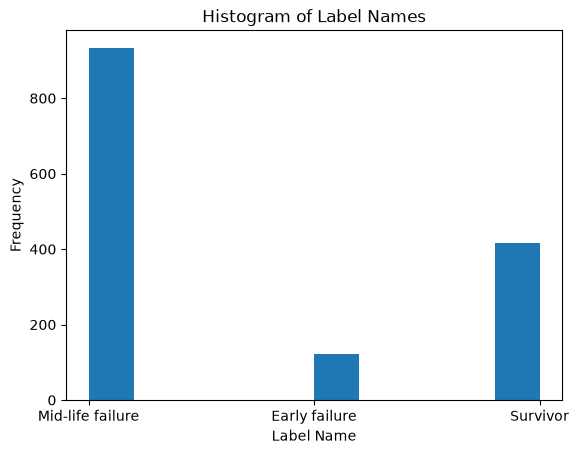

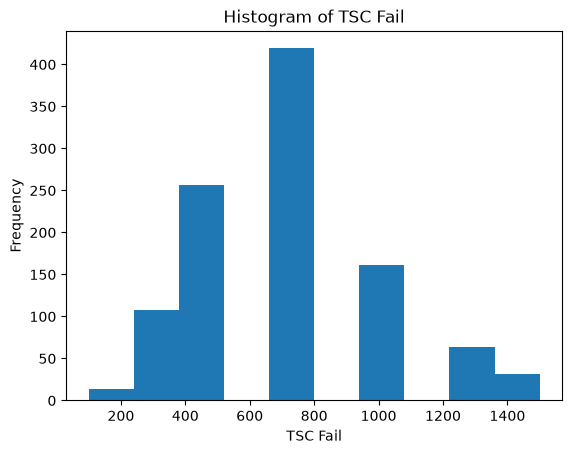

750.0: 419
nan: 415
500.0: 257
1000.0: 161
350.0: 95
1250.0: 64
1500.0: 32
250.0: 13
150.0: 7
100.0: 7


In [60]:
# plot the historgram of label
plt.hist(df['label_name'])
plt.xlabel('Label Name')
plt.ylabel('Frequency')
plt.title('Histogram of Label Names')
# show values
for label, count in df['label_name'].value_counts().items():
    print(f"{label}: {count}")
plt.show()

# plot the tsc_fail, count also the NaN values
tsc_fail_counts = df['tsc_fail'].value_counts(dropna=False)
plt.hist(df['tsc_fail'].dropna())
plt.xlabel('TSC Fail')
plt.ylabel('Frequency')
plt.title('Histogram of TSC Fail')
plt.show()


# show values including NaN
for label, count in tsc_fail_counts.items():
    print(f"{label}: {count}")

### Add binary label

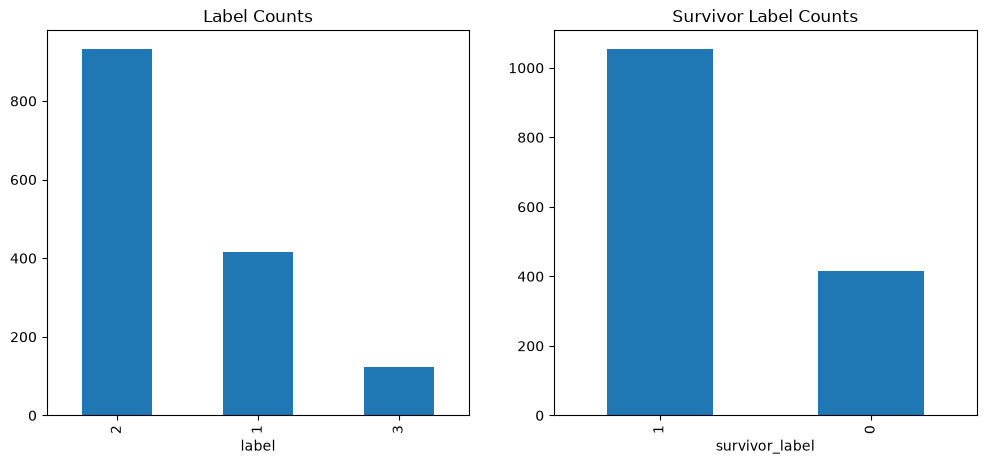

In [67]:
survivor_label = []
for i in range(len(df['tsc_fail'])):
    if (df['label'].iloc[i] == 1):   # 447 survivors
        survivor_label.append(0)
    else:
        survivor_label.append(1)

df['survivor_label'] = survivor_label
# print(df['survivor_label'])
df['survivor_label'].value_counts()

# plot the label_names and survivor_label counts in two plots
plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
df['label'].value_counts().plot(kind='bar')
plt.title('Label Counts')

plt.subplot(1, 2, 2)
df['survivor_label'].value_counts().plot(kind='bar')
plt.title('Survivor Label Counts')

plt.show()

### Prepare the Feature Matrix

In [29]:
thermal_cols = [c for c in df.columns if c.startswith("thermal_")]
elec_cols    = [c for c in df.columns if c.startswith("electrical_mean_")]
feat_cols    = thermal_cols + elec_cols 
print("Feature column length:", len(feat_cols))
print("Feature columns:", feat_cols)

# there are cell without values in the dataset, use imputer
# scale also the data before dim reduction and unsupervised
x = SimpleImputer(strategy='constant', fill_value=0).fit_transform(df[feat_cols])
x_scaled = StandardScaler().fit_transform(x)
print("Scaled feature shape:", x_scaled.shape)

Feature column length: 22
Feature columns: ['thermal_void_area_frac', 'thermal_centroid_x', 'thermal_centroid_y', 'thermal_q_NW', 'thermal_q_NE', 'thermal_q_SW', 'thermal_q_SE', 'thermal_cluster_count', 'thermal_mean_circularity', 'thermal_largest_void_frac', 'thermal_edge_proximity_min', 'electrical_mean_void_area_frac', 'electrical_mean_centroid_x', 'electrical_mean_centroid_y', 'electrical_mean_q_NW', 'electrical_mean_q_NE', 'electrical_mean_q_SW', 'electrical_mean_q_SE', 'electrical_mean_cluster_count', 'electrical_mean_mean_circularity', 'electrical_mean_largest_void_frac', 'electrical_mean_edge_proximity_min']
Scaled feature shape: (1470, 22)


### Check the Fea

## Dimensionality Reduction

Use PCA, KPCA, Isomap, UMAP to try to reduce dimension

In [30]:
# dictionary where we will put all the best embeddings
embeddings = {}

### PCA

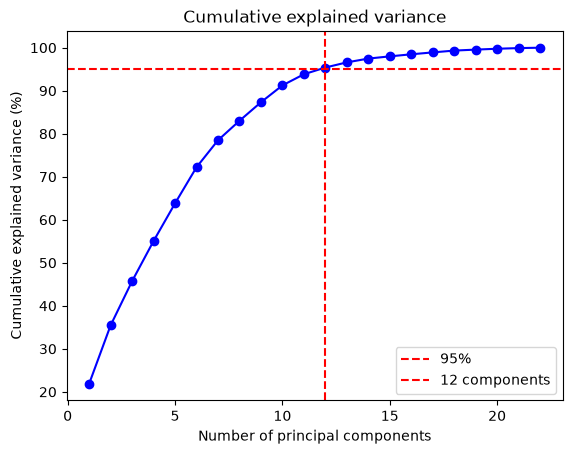

(1470, 12)
Number of components for 95% CPV: 12
Shape of PCA result for 95% CPV: (1470, 12)


In [31]:
def pca_analysis(x_scaled, feat_cols):
    # optimize PCA
    pca = PCA(n_components=len(feat_cols))
    pca_result = pca.fit_transform(x_scaled)
    var = pca.explained_variance_ratio_
    cpv = np.cumsum(var)*100
    
    

    # plot the cumulative percent variance
    plt.plot(np.arange(cpv.size)+1, cpv, 'bo-')
    plt.xlabel('Number of principal components')
    plt.ylabel('Cumulative explained variance (%)')
    plt.title('Cumulative explained variance')
    plt.axhline(95, color='r', linestyle='--', label='95%')
    plt.axvline(np.argmax(cpv >= 95) + 1, color='r', linestyle='--', label=f'{np.argmax(cpv >= 95) + 1} components')
    plt.legend()
    plt.grid(True)
    plt.grid()
    plt.show()

    n_components = np.argmax(cpv >= 95) + 1
    pca_df = pd.DataFrame(pca_result[:, :n_components], columns=[f'PC{i+1}' for i in range(n_components)])
    print(pca_df.shape)

    # pca data with 95% CPV
    n_components_95 = np.argmax(cpv >= 95) + 1
    pca_95 = PCA(n_components=n_components_95)
    pca_result_95 = pca_95.fit_transform(x_scaled)
    pca_result_95_df = pd.DataFrame(pca_result_95, columns=[f'PC{i+1}' for i in range(n_components_95)])
    print(f'Number of components for 95% CPV: {n_components_95}')
    print(f'Shape of PCA result for 95% CPV: {pca_result_95.shape}')

    return pca_result_95, pca_result_95_df, cpv

pca_result_95, pca_result_95_df, cpv = pca_analysis(x_scaled, feat_cols)

# optimize PCA
# pca = PCA(n_components=len(feat_cols))
# pca_result = pca.fit_transform(x_scaled)
# var = pca.explained_variance_ratio_
# cpv = np.cumsum(var)*100

# # plot the cumulative percent variance
# plt.plot(np.arange(cpv.size)+1, cpv, 'bo-')
# plt.xlabel('Number of principal components')
# plt.ylabel('Cumulative explained variance (%)')
# plt.title('Cumulative explained variance')
# plt.axhline(95, color='r', linestyle='--', label='95%')
# plt.axvline(np.argmax(cpv >= 95) + 1, color='r', linestyle='--', label=f'{np.argmax(cpv >= 95) + 1} components')
# plt.legend()
# plt.grid(True)
# plt.grid()
# plt.show()

# pca_df = pd.DataFrame(pca_result[:, :12], columns=[f'PC{i+1}' for i in range(12)])
# print(pca_df.shape)
# pca_df.head()

In [32]:
# pca data with 95% CPV
n_components_95 = np.argmax(cpv >= 95) + 1
pca_95 = PCA(n_components=n_components_95)
pca_result_95 = pca_95.fit_transform(x_scaled)
pca_result_95_df = pd.DataFrame(pca_result_95, columns=[f'PC{i+1}' for i in range(n_components_95)])
print(f'Number of components for 95% CPV: {n_components_95}')
print(f'Shape of PCA result for 95% CPV: {pca_result_95.shape}')
embeddings['PCA'] = pca_result_95

print(f'Embeddings for PCA: {embeddings["PCA"].shape}')
pca_result_95_df.head()

Number of components for 95% CPV: 12
Shape of PCA result for 95% CPV: (1470, 12)
Embeddings for PCA: (1470, 12)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
0,-1.444234,-0.868894,0.130200,2.057712,1.276376,3.747145,1.830149,0.560130,-0.716537,-1.641526,-0.372666,-1.173486
1,-0.642568,-4.827283,0.100872,-0.574332,-2.034888,0.444822,-2.467271,-0.096554,-1.236669,0.182779,0.712882,-0.295435
2,-1.537161,-3.860671,0.230221,0.918780,2.453337,0.617330,-2.757435,0.655930,1.637199,-1.686399,0.637474,-1.245342
3,-0.195140,-1.681555,-0.829848,-3.609944,-1.782421,0.950935,-0.868081,-1.223561,0.438222,2.576707,-0.477238,-1.025622
4,0.102638,-4.696709,0.636778,-0.194927,0.287323,2.172015,-2.574431,-0.434225,-1.759488,-1.506269,0.365888,-0.966030


#### Plotting and Inspection of 2 Principal Components

PCA showed that the dominant variance in the feature space is driven by the 'has_thermal_pad' feature. This might mean that we have to separate modeling the the with thermal pad and without thermal pad data.

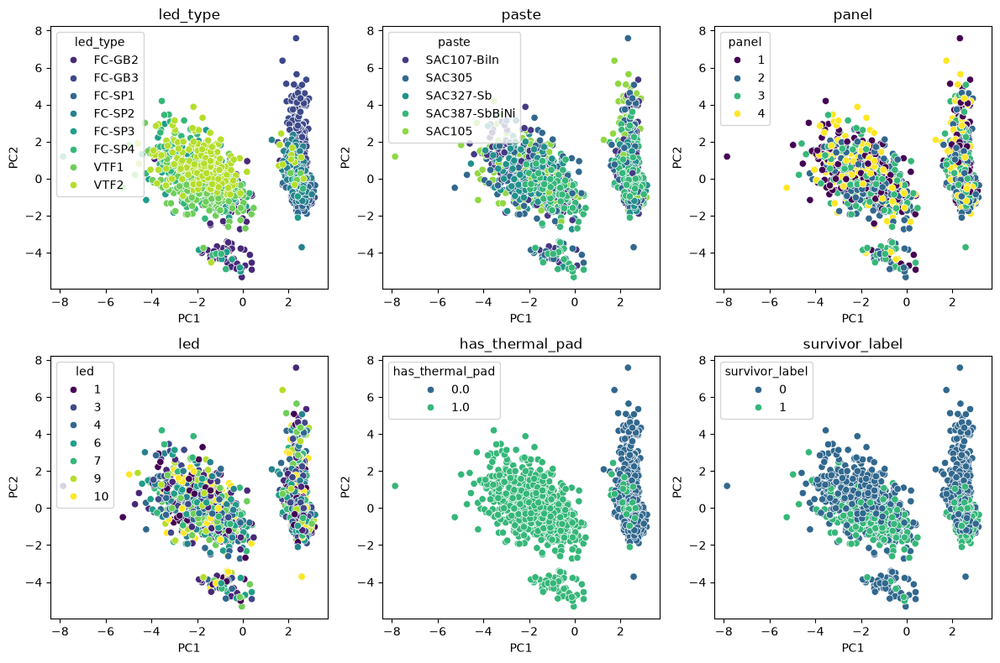

In [33]:
def inspect_dimreduction(df, dimred_result_df):

    fig, ax = plt.subplots(2, 3, figsize=(12, 8))

    for i, col in enumerate(['led_type', 'paste', 'panel', 'led', 'has_thermal_pad', 'survivor_label']):
        ax_i = ax[i // 3, i % 3]
        sns.scatterplot(data=dimred_result_df, x='PC1', y='PC2', hue=df[col], palette='viridis', ax=ax_i)
        ax_i.set_title(col)
    plt.tight_layout()
    plt.show()

inspect_dimreduction(df, pca_result_95_df)

### KPCA

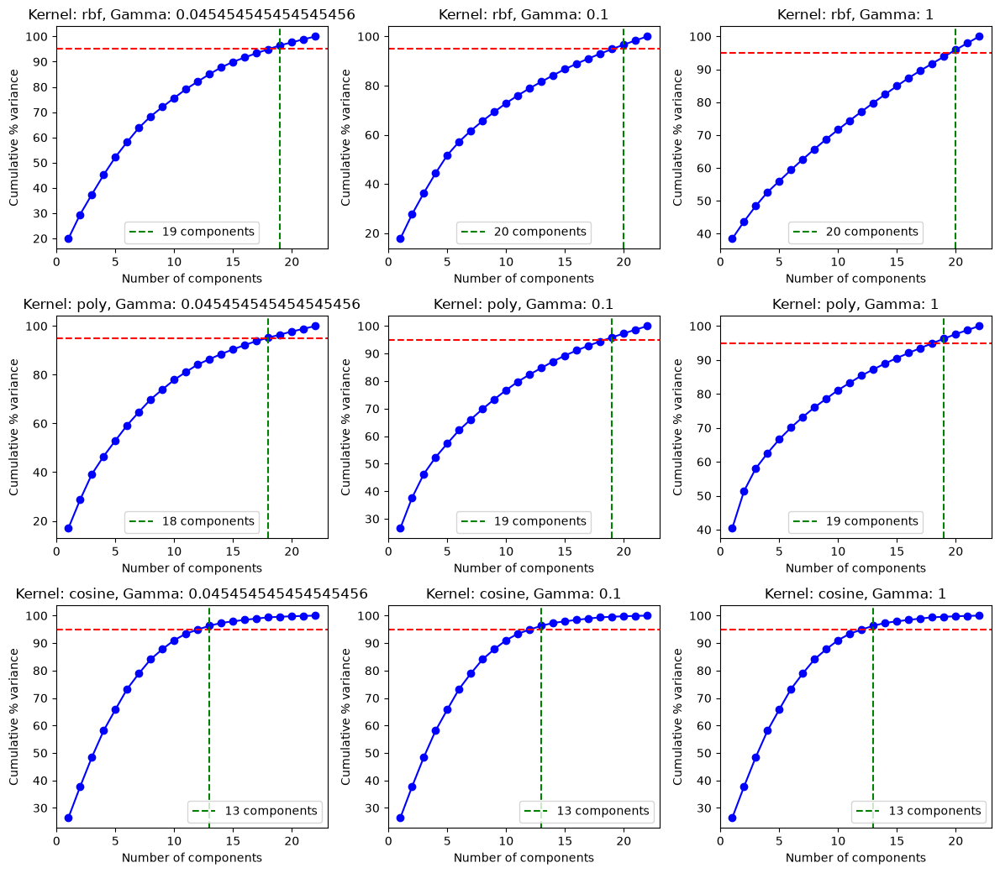

Best kernel: cosine, Best gamma: 0.045454545454545456, Minimum components: 13


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,-0.283183,-0.165768,0.165823,-0.366396,0.288974,0.582299,0.296140,-0.041265,0.314963,0.139581,-0.075551,-0.166012,-0.183200
1,-0.215144,-0.730232,0.100932,0.036334,0.267589,-0.219629,-0.461178,-0.144317,0.081734,-0.180962,0.151127,-0.032048,-0.056402
2,-0.301675,-0.562684,0.071095,-0.028961,-0.172644,0.386985,-0.468568,-0.099419,0.012637,0.384196,0.158817,-0.162691,-0.132438
3,-0.096687,-0.205800,0.218913,0.509861,0.417800,-0.231848,-0.244671,0.148418,-0.341334,-0.289470,-0.103318,-0.188536,-0.005289
4,-0.092572,-0.674338,0.070524,0.022329,0.254772,0.241785,-0.478595,-0.096422,0.352254,-0.080630,0.108729,-0.121707,-0.105335


In [34]:
kernel = ['rbf', 'poly', 'cosine']
gamma = [1/len(feat_cols), 0.1, 1]

fig, axes = plt.subplots(len(kernel), len(gamma),
                         figsize=(4 * len(gamma), 3.5 * len(kernel)),
                         squeeze=False)  # keeps axes 2D even if there's only 1 row or 1 column


# store the best kernel and gamma combination
best_kernel = None
best_gamma = None
min_components = float('inf')

for i, k in enumerate(kernel):
    for j, g in enumerate(gamma):
        kpca = KernelPCA(n_components=len(feat_cols), kernel=k, gamma=g)
        kpca_result = kpca.fit_transform(x_scaled)

        kpca_evratio = kpca.eigenvalues_ / kpca.eigenvalues_.sum()
        kpca_cpv = np.cumsum(kpca_evratio) * 100
        n95 = np.argmax(kpca_cpv >= 95) + 1

        ax = axes[i, j]
        ax.plot(np.arange(kpca_cpv.size) + 1, kpca_cpv, 'bo-')
        ax.axhline(y=95, color='r', linestyle='--')
        ax.axvline(x=n95, color='g', linestyle='--', label=f'{n95} components')
        if n95 < min_components:
            min_components = n95
            best_kernel = k
            best_gamma = g
        ax.set_title(f'Kernel: {k}, Gamma: {g}')
        ax.set_xlabel('Number of components')
        ax.set_ylabel('Cumulative % variance')
        ax.legend()

plt.tight_layout()
plt.show()

print(f'Best kernel: {best_kernel}, Best gamma: {best_gamma}, Minimum components: {min_components}')

kpca = KernelPCA(n_components=min_components, kernel=best_kernel, gamma=best_gamma)
kpca_result_95 = kpca.fit_transform(x_scaled)
kpca_result_95_df = pd.DataFrame(kpca_result_95, columns=[f'PC{i+1}' for i in range(min_components)])
embeddings['KPCA'] = kpca_result_95
kpca_result_95_df.head()



#### Plotting and Inspection of 2 Principal Components

Result of KPCA still shows that there is strong variance among the 'has_thermal_pad' feature.
<br>
And since the KPCA has 13 components, compared to PCA that has 12 components, we may opt to use PCA instead of KPCA dim reduction.

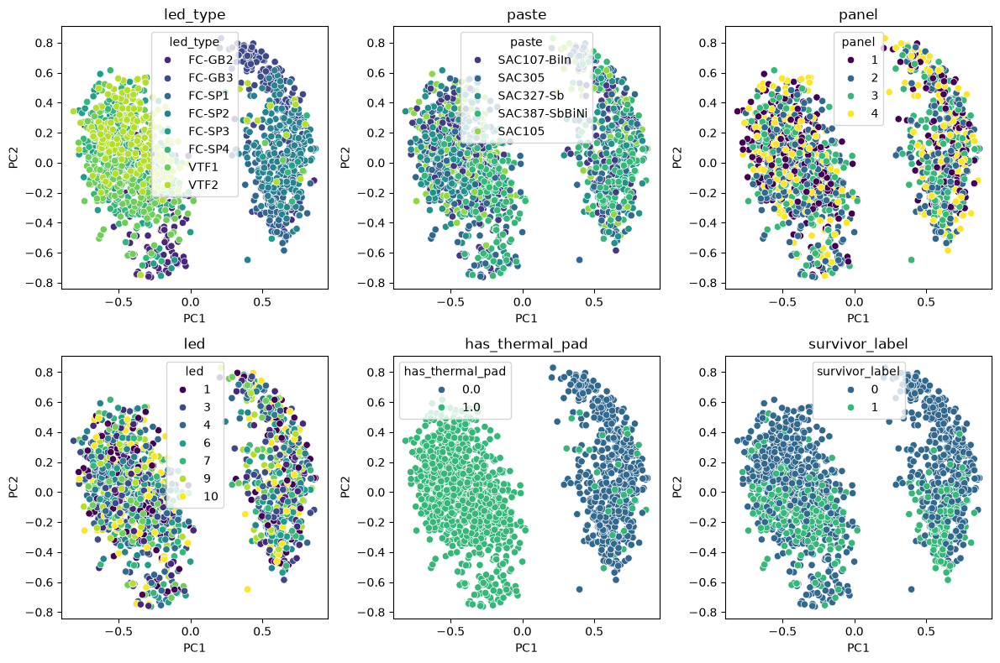

In [35]:
inspect_dimreduction(df, kpca_result_95_df)

### Isomap

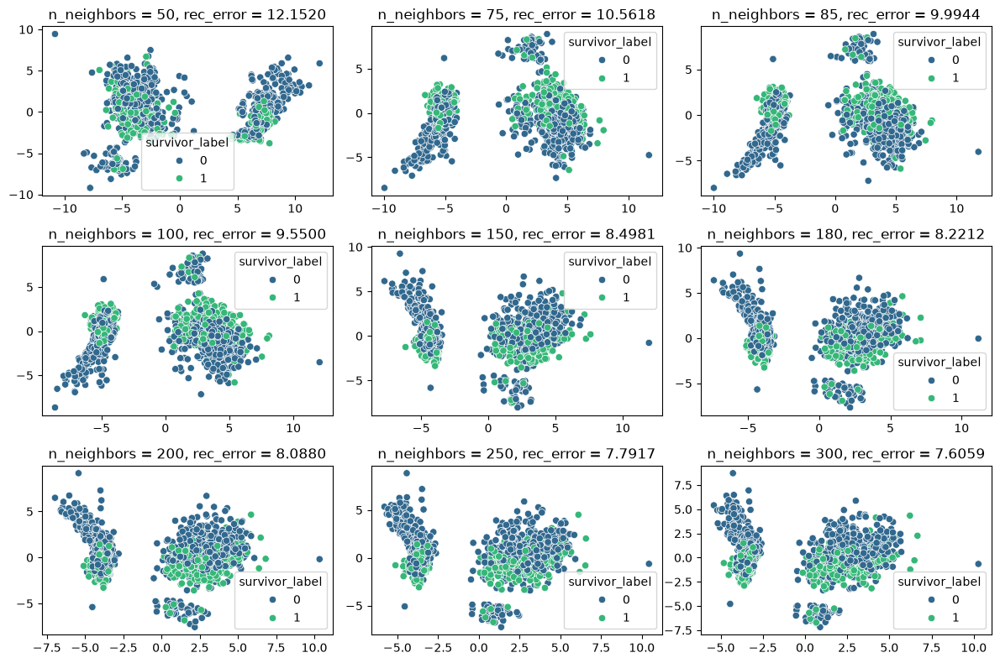

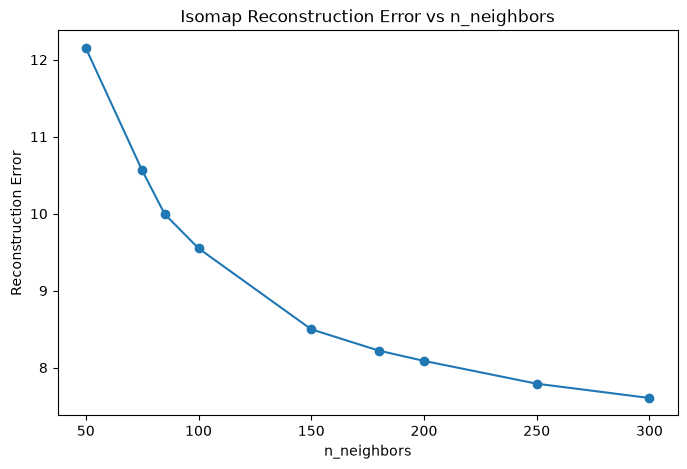

(1470, 2)

In [36]:
n_neighbors = [50, 75, 85, 100, 150, 180, 200, 250, 300]

# 2D Isomap visualization with varying n_neighbors
rec_errors = []

fig, ax = plt.subplots(3, 3, figsize=(12, 8))
for i, n in enumerate(n_neighbors):
    isomap = manifold.Isomap(n_components = 2, n_neighbors = n)
    isomap_result = isomap.fit_transform(x_scaled)
    rec_error = isomap.reconstruction_error()
    rec_errors.append(rec_error)
    ax_i = ax[i // 3, i % 3]
    sns.scatterplot(x=isomap_result[:, 0], y=isomap_result[:, 1], hue=df['survivor_label'], palette='viridis', ax=ax_i)
    ax_i.set_title(f'n_neighbors = {n}, rec_error = {rec_error:.4f}')
plt.tight_layout()
plt.show()

# plot the reconstruction error to determine which is the best hyperparameter --- lower is better
plt.figure(figsize=(8, 5))
plt.plot(n_neighbors, rec_errors, marker='o')
plt.xlabel('n_neighbors')
plt.ylabel('Reconstruction Error')
plt.title('Isomap Reconstruction Error vs n_neighbors')
plt.show()

isomap = manifold.Isomap(n_components=2, n_neighbors=150)
isomap_result_best = isomap.fit_transform(x_scaled)
isomap_result_best_df = pd.DataFrame(isomap_result_best, columns=[f'PC{i+1}' for i in range(2)])
embeddings['Isomap'] = isomap_result_best
isomap_result_best_df.shape


#### Plotting and Inspection

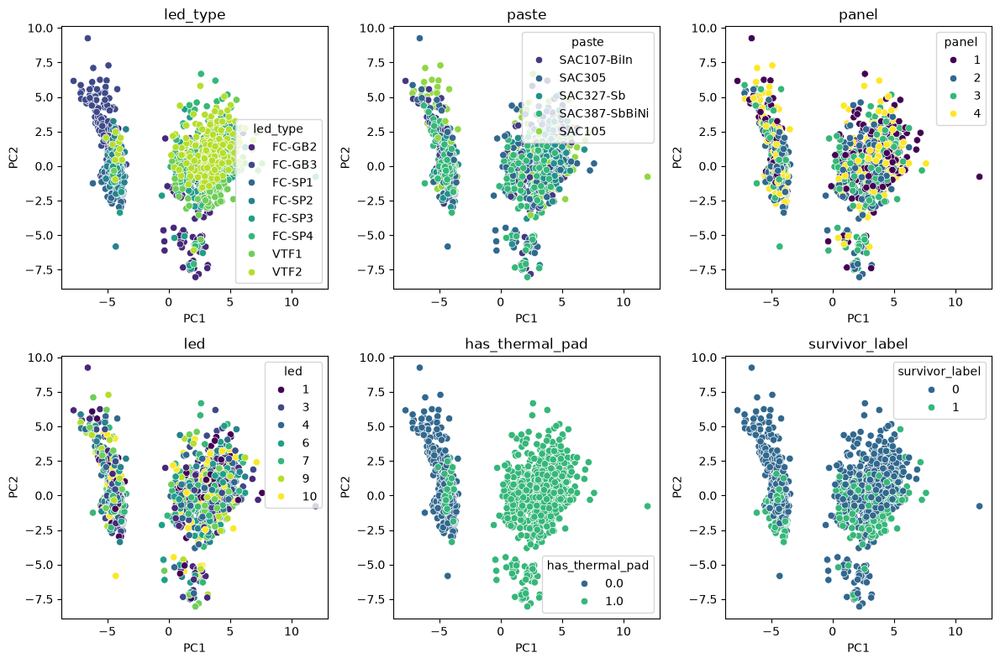

In [37]:
inspect_dimreduction(df, isomap_result_best_df)

### UMAP

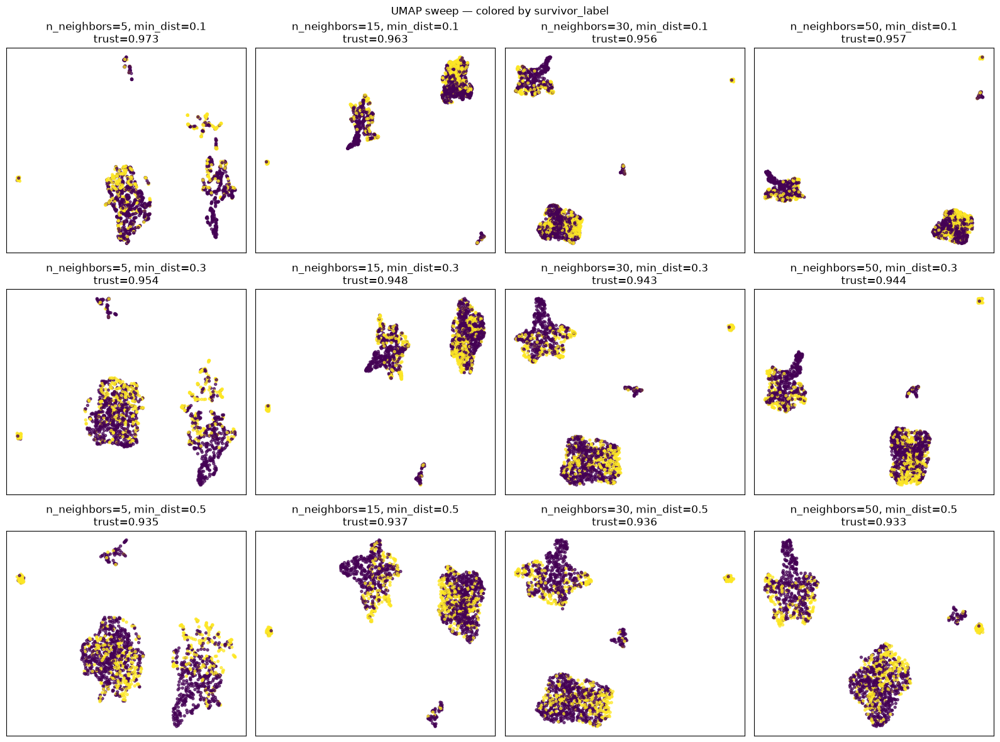


Top 5 by trustworthiness:
  n_neighbors=5, min_dist=0.1: 0.973
  n_neighbors=15, min_dist=0.1: 0.963
  n_neighbors=50, min_dist=0.1: 0.957
  n_neighbors=30, min_dist=0.1: 0.956
  n_neighbors=5, min_dist=0.3: 0.954


,PC1,PC2
0,6.533917,3.093836
1,0.215895,14.793462
2,1.665895,14.998203
3,2.736359,5.775916
4,1.173016,14.972342


In [38]:
n_neighbors = [5, 15, 30, 50]
min_dist = [0.1, 0.3, 0.5]

fig, axes = plt.subplots(len(min_dist), len(n_neighbors),
                         figsize=(16, 12))
trust_scores = {}

# 2D UMAP sweep with varying n_neighbors and min_dist

for i, md in enumerate(min_dist):
    for j, nn in enumerate(n_neighbors):
        reducer = UMAP(
            n_neighbors=nn,
            min_dist=md,
            n_components=2,
            random_state=42,
            n_jobs=1,                  # silences "n_jobs value -1 overridden to 1"
            compatibility_layout=True  # silences the FutureWarning and keeps current behavior
        )
        emb = reducer.fit_transform(x_scaled)
        trust = trustworthiness(x_scaled, emb, n_neighbors=5)
        trust_scores[(nn, md)] = trust

        ax = axes[i, j]
        ax.scatter(emb[:, 0], emb[:, 1], c=df['survivor_label'], cmap='viridis', s=8, alpha=0.7)
        ax.set_title(f'n_neighbors={nn}, min_dist={md}\ntrust={trust:.3f}')
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('UMAP sweep — colored by survivor_label')
plt.tight_layout(); plt.show()

# Rank combinations by trustworthiness
sorted_combos = sorted(trust_scores.items(), key=lambda x: -x[1])
print("\nTop 5 by trustworthiness:")
for (nn, md), score in sorted_combos[:5]:
    print(f"  n_neighbors={nn}, min_dist={md}: {score:.3f}")

# use the best parameter
best_nn, best_md = sorted_combos[0][0]
best_reducer = UMAP(
    n_neighbors=best_nn,
    min_dist=best_md,
    n_components=2,
    random_state=42,
    n_jobs=1,
    compatibility_layout=True
)
best_umap = best_reducer.fit_transform(x_scaled)
best_umap_df = pd.DataFrame(best_umap, columns=[f'PC{i+1}' for i in range(2)])
embeddings['UMAP2D'] = best_umap_df
best_umap_df.head()

#### Inspect

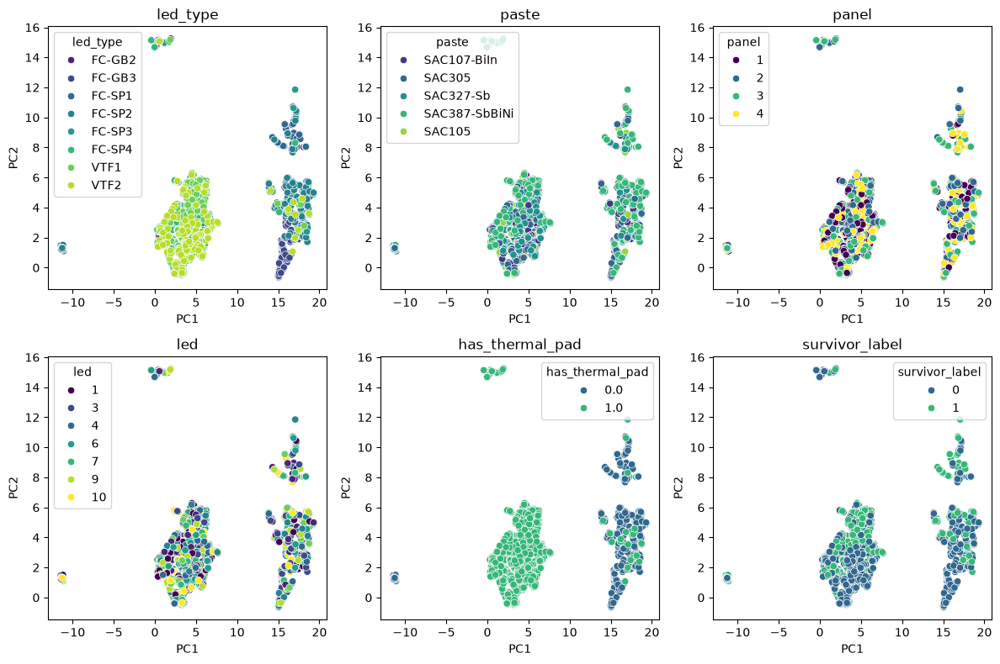

In [39]:
inspect_dimreduction(df, best_umap_df)

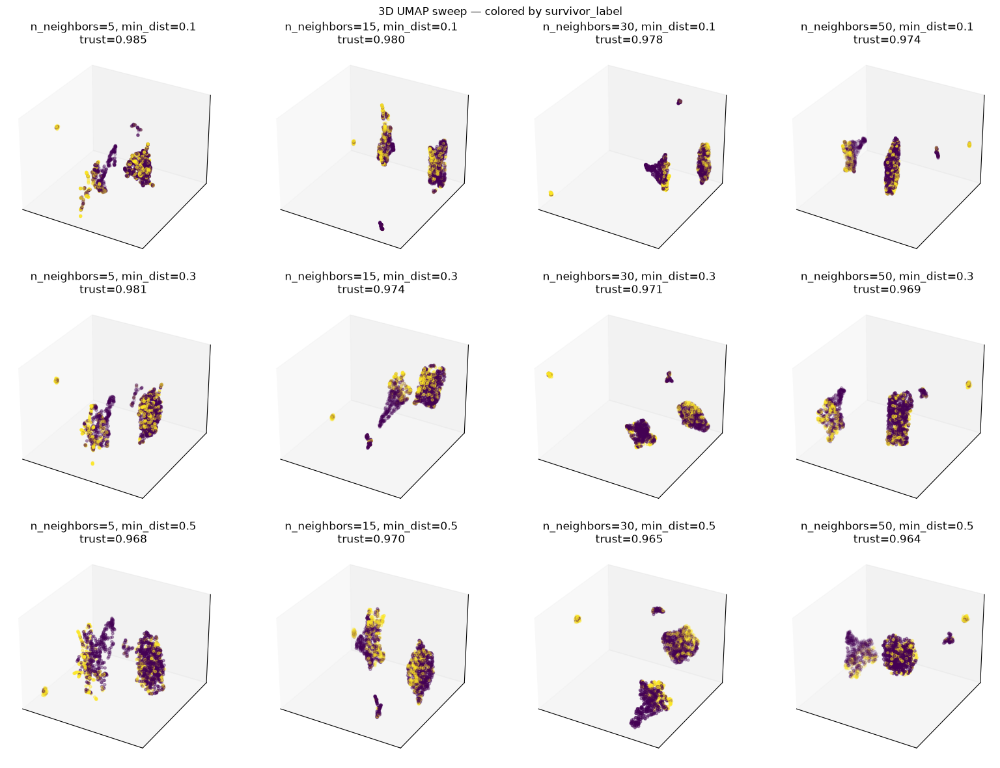


Top 5 by trustworthiness:
  n_neighbors=5, min_dist=0.1: 0.985
  n_neighbors=5, min_dist=0.3: 0.981
  n_neighbors=15, min_dist=0.1: 0.980
  n_neighbors=30, min_dist=0.1: 0.978
  n_neighbors=50, min_dist=0.1: 0.974


In [40]:
# 3Dimensional UMAP sweep with varying n_neighbors and min_dist

n_neighbors = [5, 15, 30, 50]
min_dist = [0.1, 0.3, 0.5]

fig, axes = plt.subplots(len(min_dist), len(n_neighbors),
                         figsize=(16, 12), subplot_kw={'projection': '3d'})
trust_scores = {}

for i, md in enumerate(min_dist):
    for j, nn in enumerate(n_neighbors):
        reducer = UMAP(
            n_neighbors=nn,
            min_dist=md,
            n_components=3,
            random_state=42,
            n_jobs=1,
            compatibility_layout=True
        )
        emb = reducer.fit_transform(x_scaled)
        trust = trustworthiness(x_scaled, emb, n_neighbors=5)
        trust_scores[(nn, md)] = trust

        ax = axes[i, j]
        ax.scatter(emb[:, 0], emb[:, 1], emb[:, 2], c=df['survivor_label'], cmap='viridis', s=8, alpha=0.7)
        ax.set_title(f'n_neighbors={nn}, min_dist={md}\ntrust={trust:.3f}')
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

plt.suptitle('3D UMAP sweep — colored by survivor_label')
plt.tight_layout(); plt.show()

# Rank combinations by trustworthiness
sorted_combos = sorted(trust_scores.items(), key=lambda x: -x[1])
print("\nTop 5 by trustworthiness:")
for (nn, md), score in sorted_combos[:5]:
    print(f"  n_neighbors={nn}, min_dist={md}: {score:.3f}")


## Unsupervised Learning (Thermal + Electrical)

### KMeans using x_scaled 

In [41]:
def kmeans_cluster(x_scaled, max_k=13):
    sil_scores = []
    inertias = []

    fig, ax = plt.subplots(3, 4, figsize=(18, 14))

    for k in range(2, max_k+1):
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
        cluster_labels = kmeans.fit_predict(x_scaled)
        centroids = kmeans.cluster_centers_

        sil_scores.append(silhouette_score(x_scaled, cluster_labels))
        inertias.append(kmeans.inertia_)

        a = ax[(k-2) // 4, (k-2) % 4]
        sns.scatterplot(x=x_scaled[:,0], y=x_scaled[:,1],
                        hue=cluster_labels, palette='tab10', ax=a)
        a.scatter(centroids[:,0], centroids[:,1], c='black', marker='X', s=100)
        a.set_title(f'k={k}')
        a.grid(True, which='both', linestyle='--', linewidth=0.5)

    plt.tight_layout()
    plt.show()

    fig2, ax2 = plt.subplots(1, 2, figsize=(12, 5))
    ax2[0].plot(range(2, max_k+1), sil_scores, 'o-')
    ax2[0].set_title('Silhouette Scores')
    ax2[0].set_xlabel('k Clusters')
    ax2[0].set_ylabel('Silhouette Score')
    ax2[0].grid(True, which='both', linestyle='--', linewidth=0.5)

    ax2[1].plot(range(2, max_k+1), inertias, 'o-')
    ax2[1].set_title('Inertia')
    ax2[1].set_xlabel('k Clusters')
    ax2[1].set_ylabel('Inertia')
    ax2[1].grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.show()


    # getting the optimal k
    optimal_k = sil_scores.index(max(sil_scores)) + 2
    kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
    kmeans.fit_transform(x_scaled)
    cluster_labels = kmeans.labels_

    sns.scatterplot(x=x_scaled[:,0], y=x_scaled[:,1], hue=cluster_labels, palette='tab10')
    plt.title(f"Cluster Labels for Optimal k={optimal_k}")
    plt.show()

    return optimal_k, cluster_labels

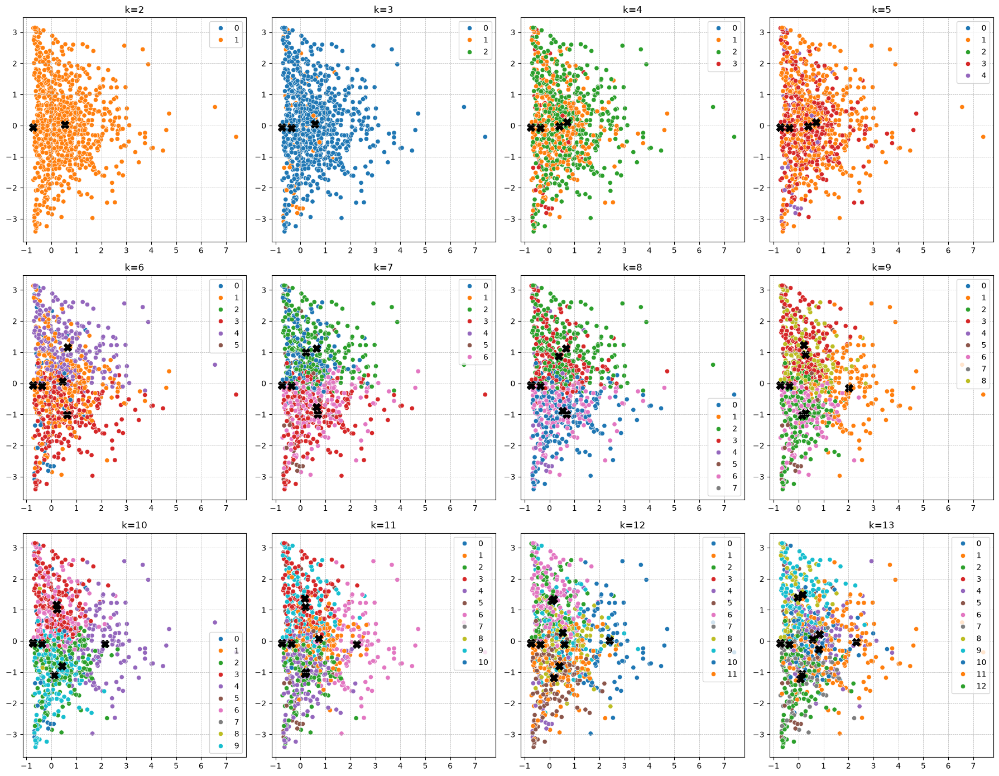

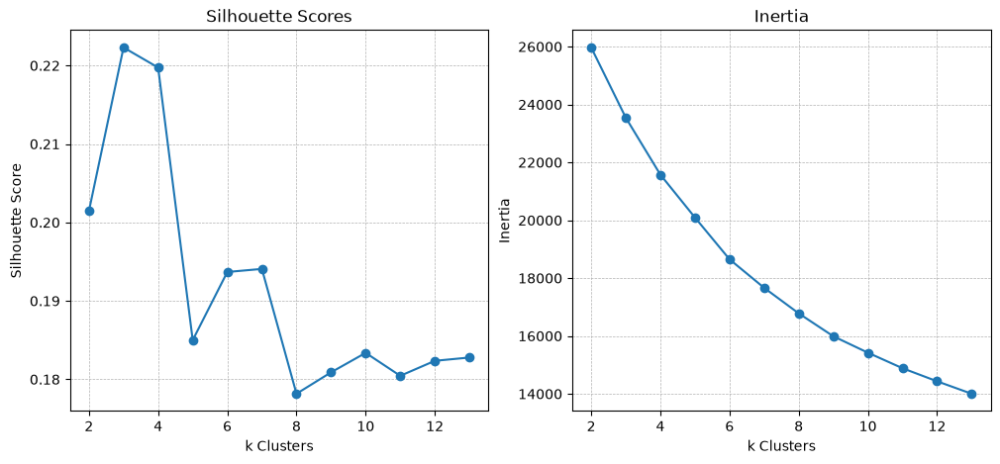

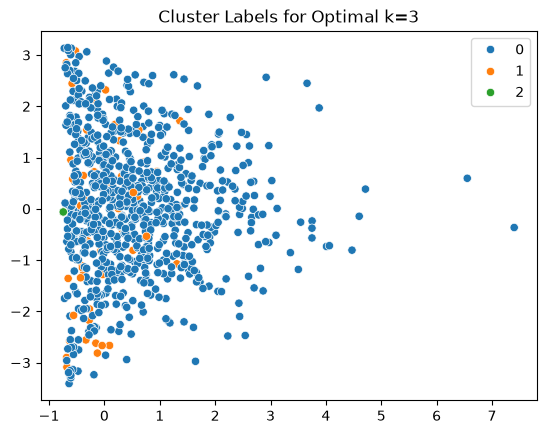

In [42]:
optimal_k, cluster_labels = kmeans_cluster(x_scaled, max_k=13)

### PCA Result + KMeans + t-SNE

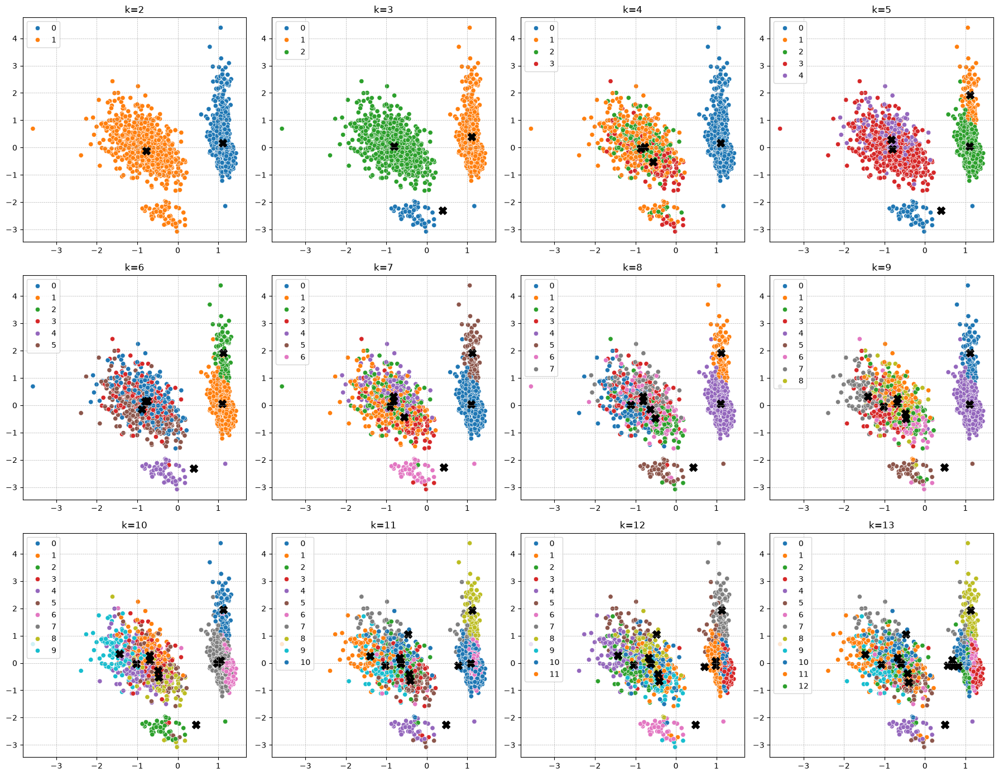

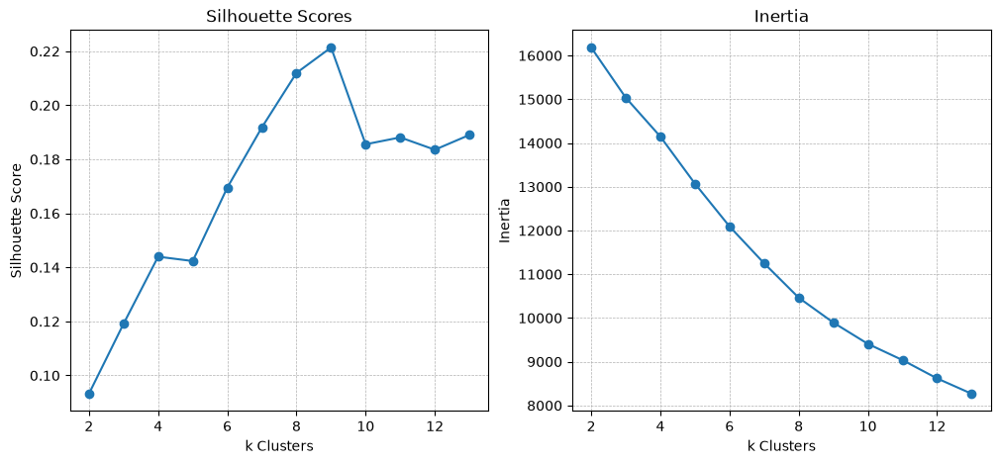

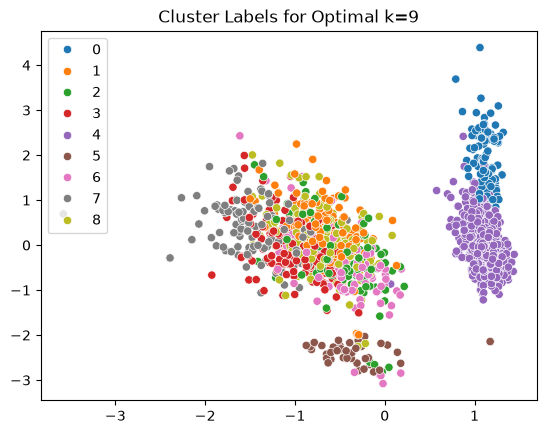

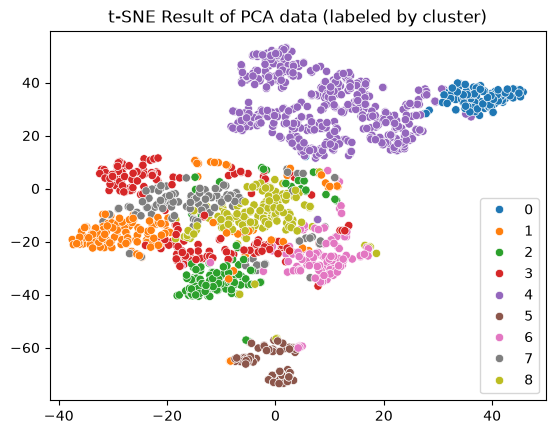

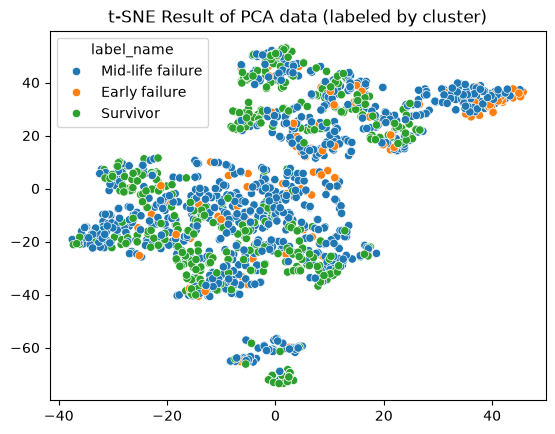

In [43]:
# perform pca with whiten=True
pca = PCA(n_components=0.95, whiten=True, random_state=42)
pca_for_unsup = pca.fit_transform(x_scaled)

# find the optimize kmeans using pca_for_unsup
optimal_k, cluster_labels = kmeans_cluster(pca_for_unsup)


# apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(pca_for_unsup)

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=cluster_labels, palette='tab10')
plt.title("t-SNE Result of PCA data (labeled by cluster)")
plt.show()

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=df['label_name'], palette='tab10')
plt.title("t-SNE Result of PCA data (labeled by cluster)")
plt.show()

### Isomap Result + KMeans + t-SNE

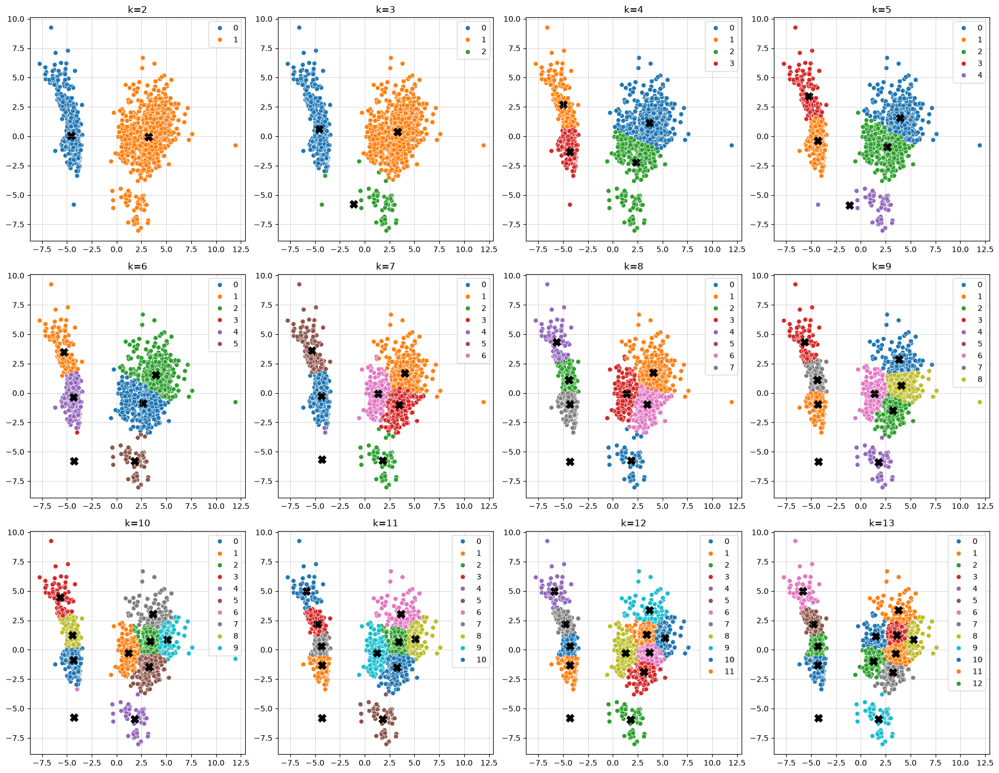

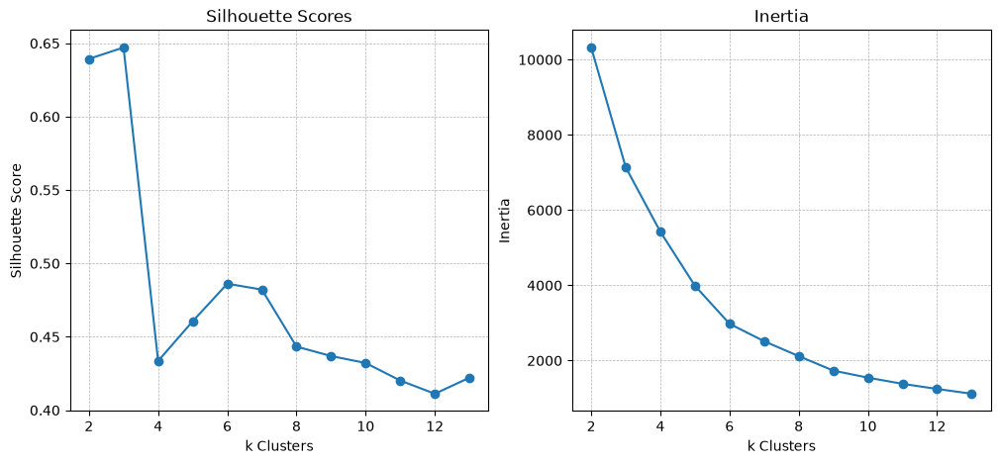

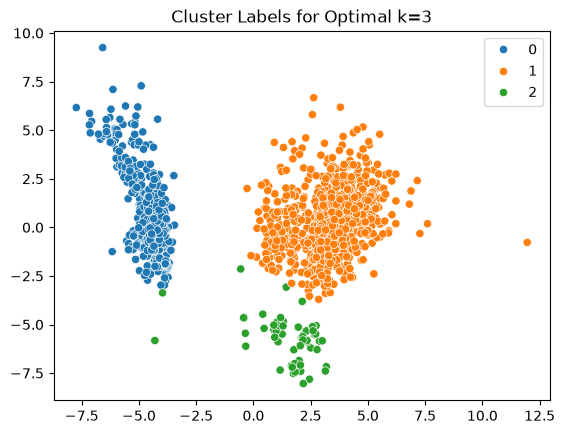

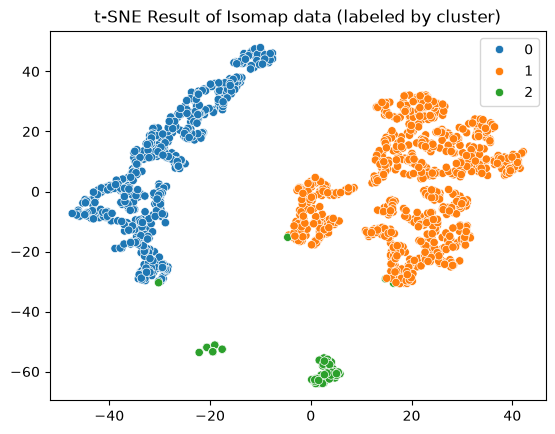

In [44]:
optimal_k, cluster_labels = kmeans_cluster(isomap_result_best, max_k=13)

# apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(isomap_result_best)

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=cluster_labels, palette='tab10')
plt.title("t-SNE Result of Isomap data (labeled by cluster)")
plt.show()

### UMAP Result + KMeans + t-SNE

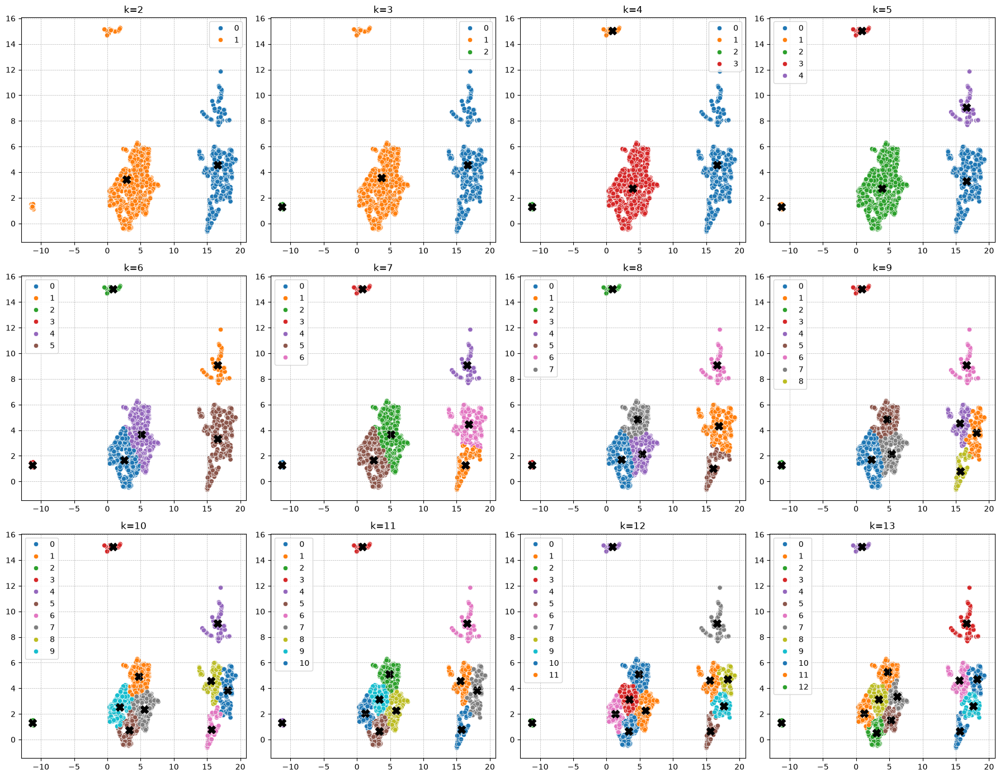

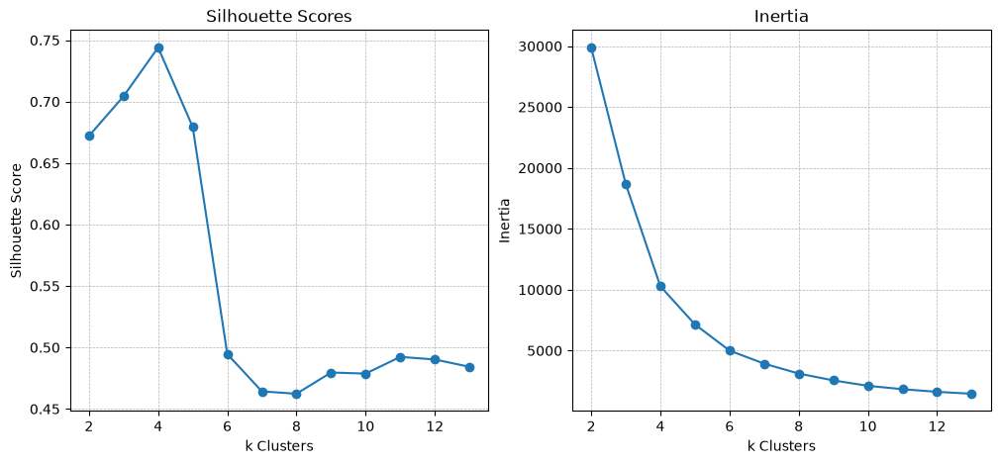

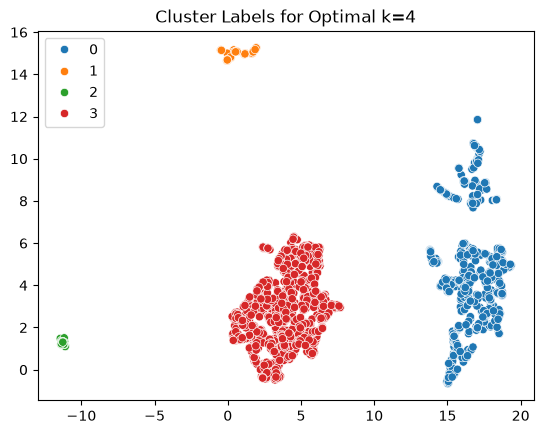

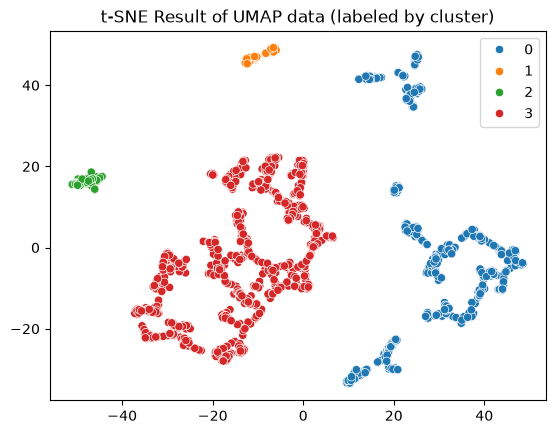

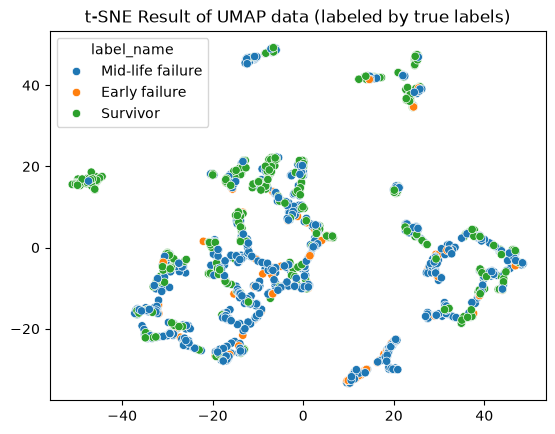

In [45]:
optimal_k, cluster_labels = kmeans_cluster(best_umap, max_k=13)

# apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(best_umap)

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=cluster_labels, palette='tab10')
plt.title("t-SNE Result of UMAP data (labeled by cluster)")
plt.show()

sns.scatterplot(x=tsne_result[:,0], y=tsne_result[:,1], hue=df['label_name'], palette='tab10')
plt.title("t-SNE Result of UMAP data (labeled by true labels)")
plt.show()

## Unsupervised Learning (One-hot Encoded based on 'has_thermal_pad')

### Separate per 'has_thermal_pad' Features

In [46]:
# has thermal pad (use only thermal pad features)
df_thpad = df[df['has_thermal_pad'] == 1].copy()
x_thpad = df_thpad[thermal_cols].dropna(axis=0)
x_thpad.head(10)
xth_scaled = StandardScaler().fit_transform(x_thpad)
print(xth_scaled.shape)

# has electrical pad (use only electrical pad features)
df_elpad = df[df['has_thermal_pad'] == 0].copy()
x_elpad = df_elpad[elec_cols].dropna(axis=0)
x_elpad.head(10)
xel_scaled = StandardScaler().fit_transform(x_elpad)
print(xel_scaled.shape)

(908, 11)
(562, 11)


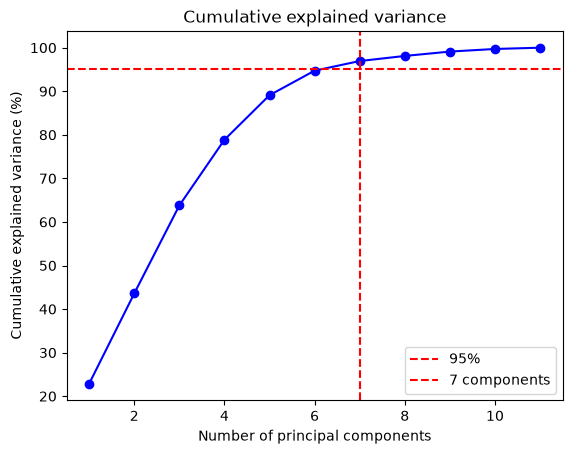

(908, 7)
Number of components for 95% CPV: 7
Shape of PCA result for 95% CPV: (908, 7)


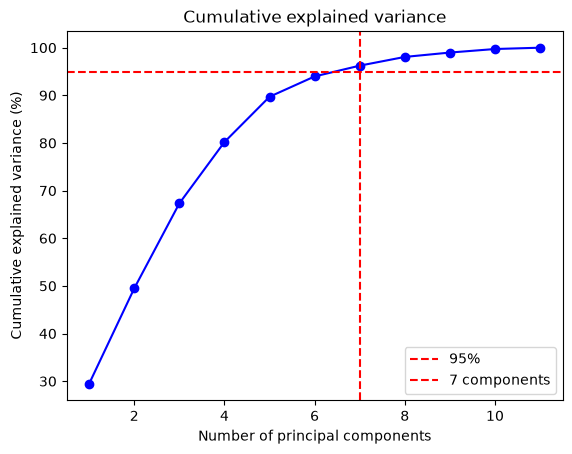

(562, 7)
Number of components for 95% CPV: 7
Shape of PCA result for 95% CPV: (562, 7)


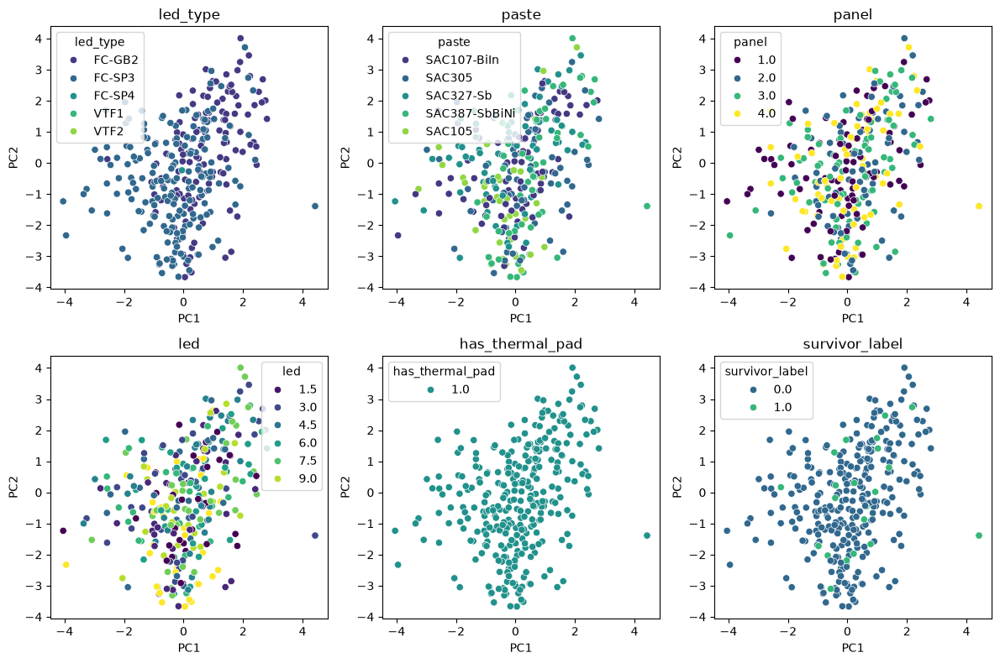

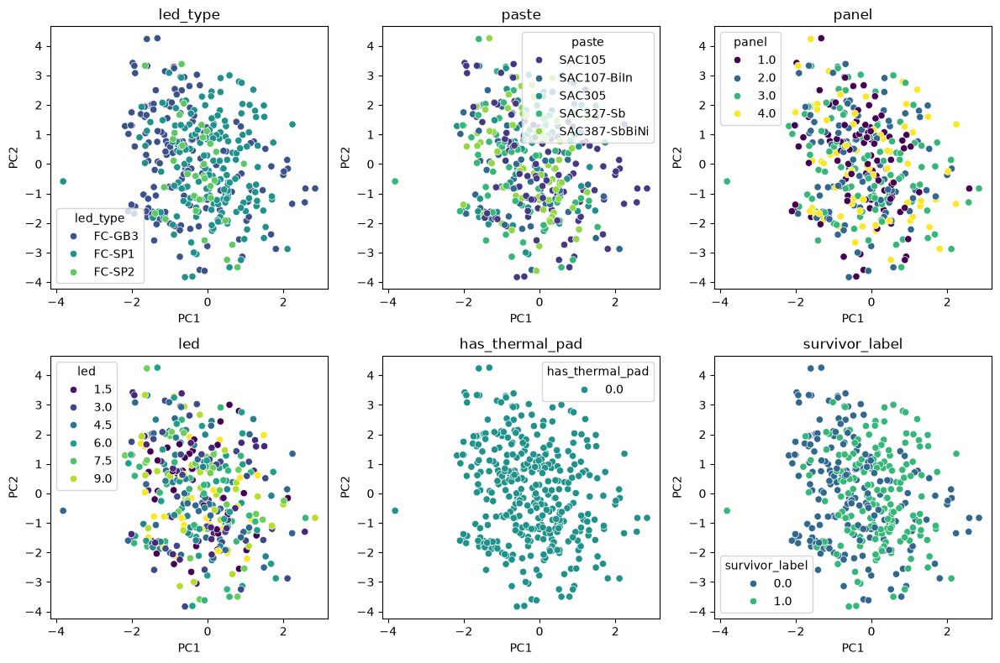

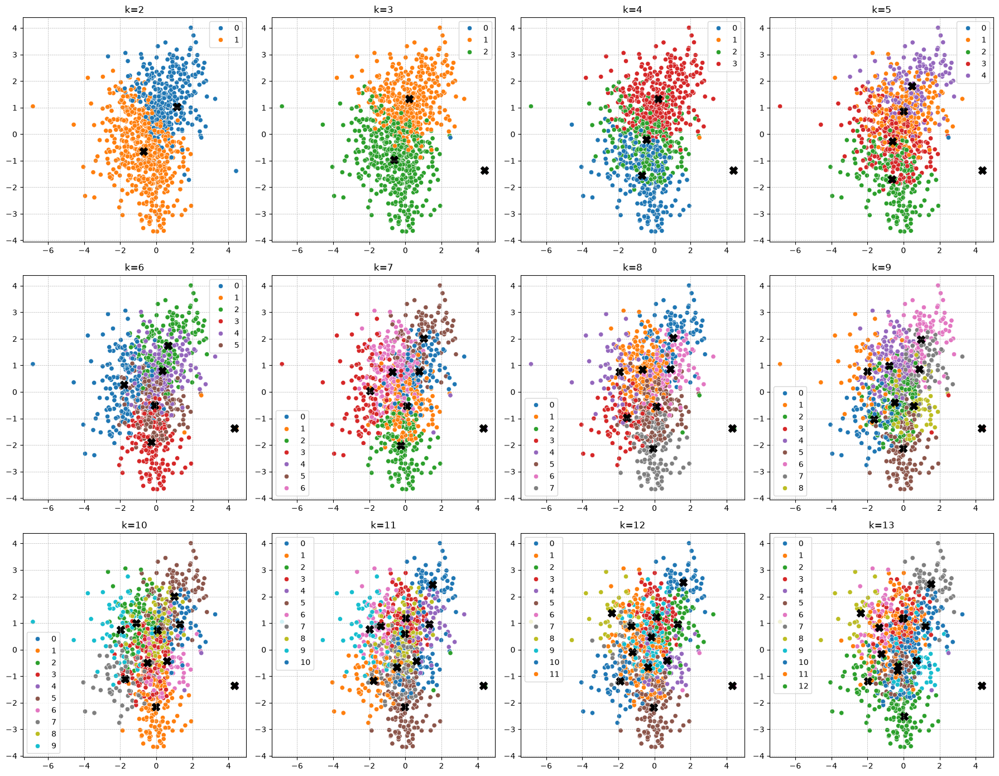

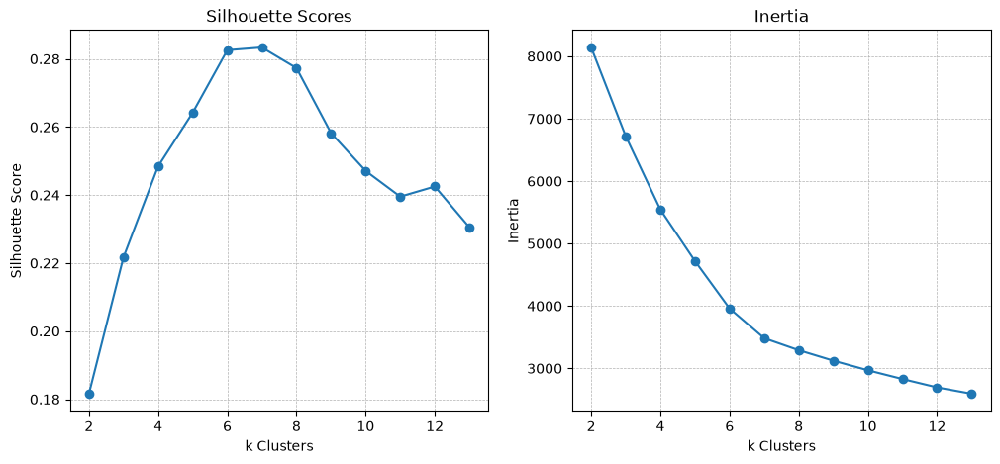

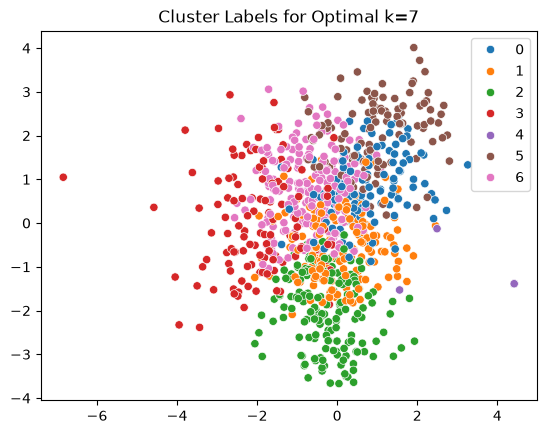

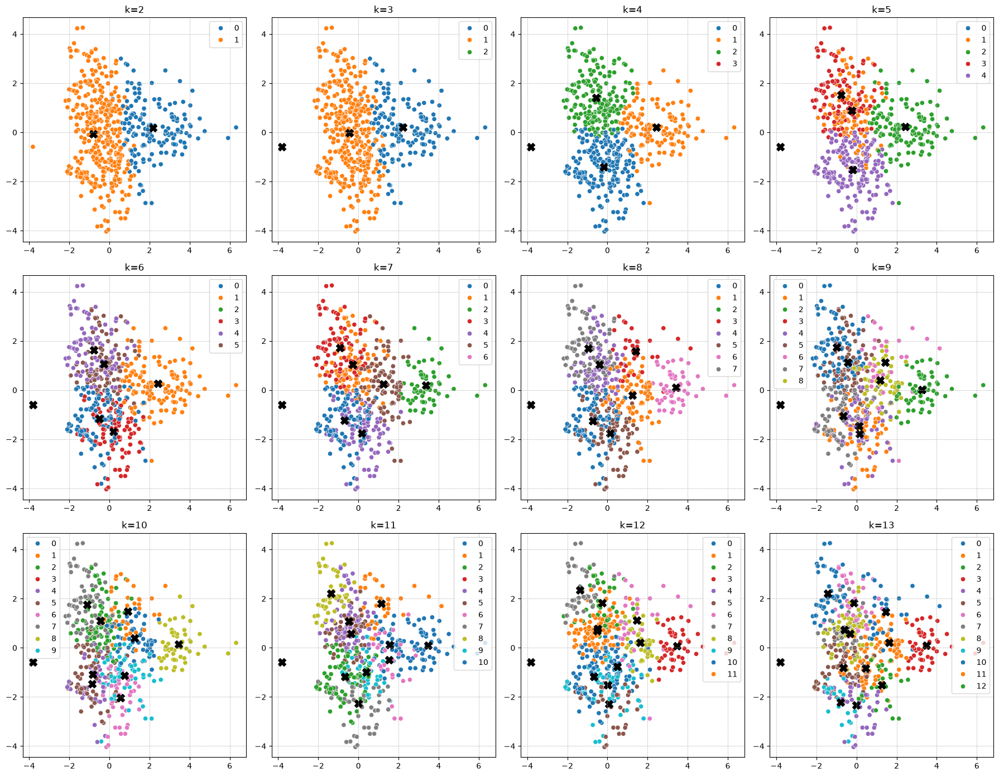

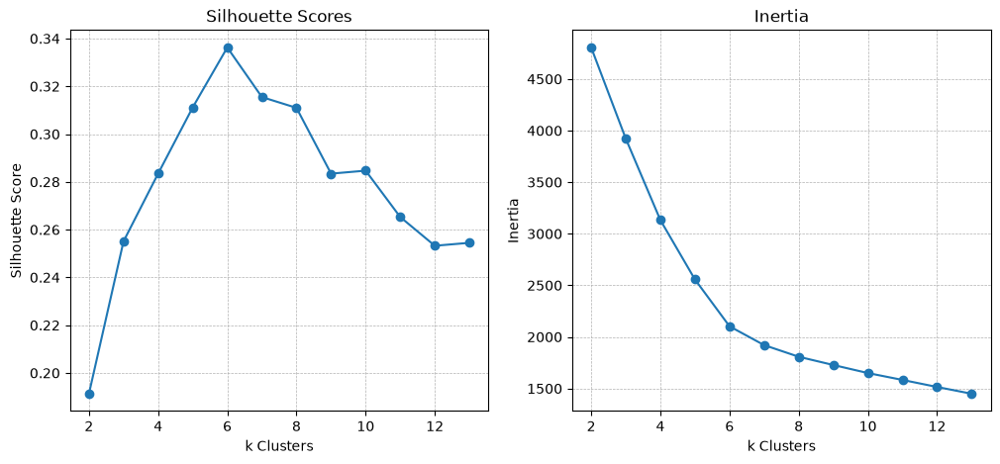

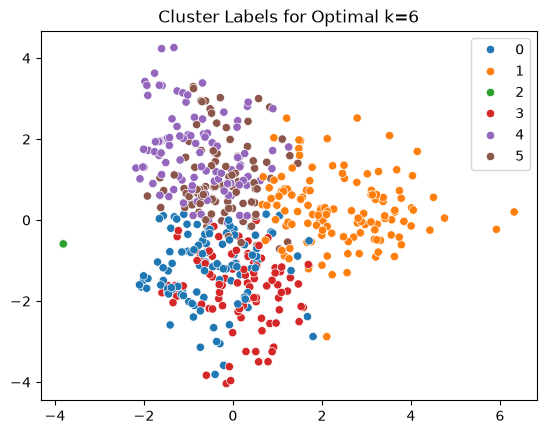

In [47]:
# Separating the PCA, 

th_pca, th_pca_df, th_cpv = pca_analysis(xth_scaled, thermal_cols)
el_pca, el_pca_df, el_cpv = pca_analysis(xel_scaled, elec_cols)

inspect_dimreduction(df_thpad, th_pca_df)
inspect_dimreduction(df_elpad, el_pca_df)

optimal_k_th, clusters_th = kmeans_cluster(th_pca)
optimal_k_el, clusters_el = kmeans_cluster(el_pca)

## Supervised Learning (Using PCA results)

In [48]:
import optuna
from optuna.trial import FixedTrial
from optuna.samplers import TPESampler
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
from optuna.visualization._optimization_history import _get_optimization_history_info_list

from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score, classification_report
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingClassifier, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.svm import SVC, SVR


import time


### Split data into Train and Test (Binary Label)

In [49]:
pca_result_95

array([[-1.44423353, -0.86889446,  0.13019956, ..., -1.64152601,
        -0.37266554, -1.17348613],
       [-0.64256772, -4.82728331,  0.10087237, ...,  0.18277867,
         0.71288215, -0.29543519],
       [-1.53716081, -3.86067073,  0.2302206 , ..., -1.6863993 ,
         0.63747369, -1.24534212],
       ...,
       [-1.02508477,  0.4712743 ,  0.8137946 , ...,  0.89379597,
         0.13833317, -0.4853155 ],
       [-1.9104343 , -0.28180145,  0.70432934, ...,  0.96700733,
        -0.42650171, -0.4709942 ],
       [-1.59154443,  0.2964795 ,  0.7678509 , ...,  0.34908474,
        -0.01884414, -0.40878553]], shape=(1470, 12))

In [50]:
x = pca_result_95
y = df['survivor_label'].to_numpy(dtype=int)
print("x shape:", x.shape, "| dtype:", x.dtype, "| NaNs:", np.isnan(x).sum())
print("y shape:", y.shape, "| dtype:", y.dtype, "| NaNs:", np.isnan(y).sum())

# split the data to train and Test
#stratify by a combination of survivor_label and has_thermal_pad
strat_key = df['survivor_label'].astype(str) + '_' + df['has_thermal_pad'].astype(str)
print("\nstrat_key shape:", strat_key.shape, "| NaNs:", strat_key.isna().sum(), "| Unique values:", strat_key.nunique())

# split the data into training and testing sets using the stratification key
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42, stratify=strat_key)
print("\nx_train shape:", x_train.shape, "| x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape, "| y_test shape:", y_test.shape)
print("x_train NaNs:", np.isnan(x_train).sum(), "| x_test NaNs:", np.isnan(x_test).sum())
print("y_train NaNs:", np.isnan(y_train).sum(), "| y_test NaNs:", np.isnan(y_test).sum())


x shape: (1470, 12) | dtype: float64 | NaNs: 0
y shape: (1470,) | dtype: int64 | NaNs: 0

strat_key shape: (1470,) | NaNs: 0 | Unique values: 4

x_train shape: (1029, 12) | x_test shape: (441, 12)
y_train shape: (1029,) | y_test shape: (441,)
x_train NaNs: 0 | x_test NaNs: 0
y_train NaNs: 0 | y_test NaNs: 0


### Create Model

In [51]:
def create_model(trial, model_type):

    if model_type == "SVC":
        kernel = trial.suggest_categorical('SVC_kernel', ['linear', 'poly', 'rbf', 'sigmoid'])
        C = trial.suggest_float('SVC_C', 1, 100, log=True)
        gamma = trial.suggest_float('SVC_gamma', 1e-4, 1, log=True)
        degree = trial.suggest_int('SVC_degree', 1, 3, step=1)
        coef0 = trial.suggest_float('SVC_coef', 0.1, 10, log=True)
        model = SVC(kernel=kernel, C=C, gamma=gamma, degree=degree, coef0=coef0)

    if model_type == "SVR":
        kernel = trial.suggest_categorical('SVR_kernel', ['linear', 'poly', 'rbf', 'sigmoid'])
        C = trial.suggest_float('SVR_C', 0.1, 100, log=True)
        gamma = trial.suggest_float('SVR_gamma', 0.1, 100, log=True)
        degree = trial.suggest_int('SVR_degree', 1, 3, step=1)
        coef0 = trial.suggest_float('SVR_coef', 0.1, 10, log=True)
        epsilon = trial.suggest_float('SVR_epsilon', 0.01, 0.1, log=True)
        model = SVR(kernel=kernel, C=C, gamma=gamma, degree=degree, epsilon=epsilon, coef0=coef0)

    if model_type == "MLPClassifier":
        params = {
                    'learning_rate_init': trial.suggest_float('learning_rate_init', 0.0001, 0.1, log=True),
                    'first_layer_neuron': trial.suggest_int('first_layer_neurons', 10, 100, step=1),
                    'second_layer_neuron': trial.suggest_int('second_layer_neurons', 10, 100, step=1),
                    'activation': trial.suggest_categorical('activation', ['tanh', 'identity', 'relu', 'logistic']),
                    'alpha': trial.suggest_float('MLP_alpha', 1e-5, 1e-1, log=True)
        }
        model = MLPClassifier(hidden_layer_sizes=(params['first_layer_neuron'], params['second_layer_neuron']),
                             learning_rate_init=params['learning_rate_init'],
                             activation=params['activation'],
                             alpha=params['alpha'],
                             max_iter=500,  # Give it enough room to learn
                             early_stopping=True, #Crucial for stability and preventing NaN crashes
                             random_state=1)

    if model_type == "MLPRegressor":
            params = {
                        'learning_rate_init': trial.suggest_float('learning_rate_init', 0.0001, 0.01, log=True),
                        'first_layer_neuron': trial.suggest_int('first_layer_neurons', 10, 100, step=1),
                        'second_layer_neuron': trial.suggest_int('second_layer_neurons', 10, 100, step=1),
                        'activation': trial.suggest_categorical('activation', ['tanh', 'identity', 'relu', 'logistic']),
                        'alpha' : trial.suggest_float('MLP_alpha', 1e-5, 1e-1, log=True)
            }
            model = MLPRegressor(hidden_layer_sizes=(params['first_layer_neuron'], params['second_layer_neuron']),
                                 learning_rate_init=params['learning_rate_init'],
                                 activation=params['activation'],
                                 alpha=params['alpha'],    
                                 max_iter=500,  # Give it enough room to learn
                                 early_stopping=True, #Crucial for stability and preventing NaN crashes
                                 random_state=1)

    if model_type == 'RandomForestClassifier':
        n_estimators = trial.suggest_int('RFC_n_estimators', 50, 300, step=50)
        max_features = trial.suggest_categorical('RFC_max_features', ['sqrt', 'log2', None])
        max_depth = trial.suggest_int('RFC_max_depth', 2, 32, log=True)
        criterion = trial.suggest_categorical('RFC_criterion', ['gini', 'entropy', 'log_loss'])
        model = RandomForestClassifier(n_estimators=n_estimators,
                                       max_features=max_features,
                                       max_depth=max_depth,
                                       criterion=criterion,
                                       random_state=42)

    if model_type == 'RandomForestRegressor':
        n_estimators = trial.suggest_int('RFR_n_estimators', 50, 300, step=50)
        max_features = trial.suggest_categorical(
            'RFR_max_features', ['sqrt', 'log2', None , 1.0]
        )
        max_depth = trial.suggest_int(
            'RFR_max_depth', 5, 30
        )  # Removed log=True for depth
        min_samples_split = trial.suggest_int('RFR_min_samples_split', 2, 10)
        min_samples_leaf = trial.suggest_int('RFR_min_samples_leaf', 1, 5)

        model = RandomForestRegressor(n_estimators=n_estimators,
                                  max_features=max_features,
                                  max_depth=max_depth,
                                  min_samples_split=min_samples_split,
                                  min_samples_leaf=min_samples_leaf,
                                  random_state=42)

    if model_type == 'HistGradientBoostingClassifier':
        max_iter = trial.suggest_int('GBC_max_estimators', 50, 300, step=50)
        learning_rate = trial.suggest_float('GBC_learning_rate',  0.01, 0.2, log=True)
        max_depth = trial.suggest_int('GBC_max_depth', 2, 32, log=True)
        model = HistGradientBoostingClassifier(max_iter=max_iter,
                                               learning_rate=learning_rate,
                                               max_depth=max_depth,
                                               random_state=42)

    if model_type == 'GradientBoostingRegressor':
        n_estimators = trial.suggest_int('GBR_n_estimators', 50, 300, step=50)
        learning_rate = trial.suggest_float('GBR_learning_rate', 0.01, 0.2, log=True)
        max_depth = trial.suggest_int('GBR_max_depth', 2, 32, log=True)
        subsample = trial.suggest_float('GBR_subsample', 0.6, 1.0)
        min_samples_split = trial.suggest_int('GBR_min_samples_split', 2, 10)

        model = GradientBoostingRegressor(n_estimators=n_estimators,
                                        learning_rate=learning_rate,
                                        max_depth=max_depth,
                                        subsample=subsample,
                                        min_samples_split=min_samples_split,
                                        random_state=42)
        
    if trial.should_prune():
        raise optuna.TrialPruned()

    return model


In [52]:
def objective(trial, model_type):
    model = create_model(trial, model_type)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(model,
                             x_train,
                             y_train,
                             cv=skf,
                             scoring='accuracy',)
    return np.mean(scores)

In [53]:
def run_model(model_type):
    sampler = TPESampler(seed=42)
    
    study = optuna.create_study(direction='maximize',
                                sampler=sampler)
    optuna_start = time.time()

    study.optimize(lambda trial: objective(trial, model_type), n_trials=50) # lambda inserts the additional parameter na model
    
    best_params = study.best_params
    print("\n\nBest Parameters: ", best_params)
    total_time = time.time() - optuna_start
    
    score = study.best_value
    print("Accuracy: ", score)
    print("Runtime: %.4f sec" % total_time)
    # store the best trial of the model
    best_model = create_model(study.best_trial, model_type)
    
    print("Best Models: ", best_model)
    

    # return best_params, best_models, score
    return best_model, study, score

In [54]:
best_classifiers = []
classifier_studies = []
classifier_score = []

for model_type in ['SVC', 'MLPClassifier', 'RandomForestClassifier', 'HistGradientBoostingClassifier']:
    best_model, study, score = run_model(model_type)
    best_classifiers.append(best_model)
    classifier_studies.append(study)
    classifier_score.append(score)

    

[I 2026-11-28 15:40:19,447] A new study created in memory with name: no-name-9b0996f8-52aa-44ff-83a2-6daf53bc697b
[I 2026-11-28 15:40:19,529] Trial 0 finished with value: 0.7172010419133317 and parameters: {'SVC_kernel': 'poly', 'SVC_C': 2.05133826308745, 'SVC_gamma': 0.0004207053950287938, 'SVC_degree': 1, 'SVC_coef': 5.3994844097874335}. Best is trial 0 with value: 0.7172010419133317.
[I 2026-11-28 15:40:19,604] Trial 1 finished with value: 0.7414870944825953 and parameters: {'SVC_kernel': 'sigmoid', 'SVC_C': 46.22589001020831, 'SVC_gamma': 0.0007068974950624604, 'SVC_degree': 1, 'SVC_coef': 0.2327067708383781}. Best is trial 1 with value: 0.7414870944825953.
[I 2026-11-28 15:40:19,661] Trial 2 finished with value: 0.7172010419133317 and parameters: {'SVC_kernel': 'poly', 'SVC_C': 16.73808578875213, 'SVC_gamma': 0.0003613894271216529, 'SVC_degree': 1, 'SVC_coef': 0.5404103854647329}. Best is trial 1 with value: 0.7414870944825953.
[I 2026-11-28 15:40:19,716] Trial 3 finished with val



Best Parameters:  {'SVC_kernel': 'rbf', 'SVC_C': 12.472381236292348, 'SVC_gamma': 0.01588720774706367, 'SVC_degree': 1, 'SVC_coef': 0.6972051803383379}
Accuracy:  0.8114752545583709
Runtime: 4.8961 sec
Best Models:  SVC(C=12.472381236292348, coef0=0.6972051803383379, degree=1,
    gamma=0.01588720774706367)


[I 2026-11-28 15:40:24,709] Trial 0 finished with value: 0.7706369879232773 and parameters: {'learning_rate_init': 0.0013292918943162175, 'first_layer_neurons': 96, 'second_layer_neurons': 76, 'activation': 'tanh', 'MLP_alpha': 0.029154431891537533}. Best is trial 0 with value: 0.7706369879232773.
[I 2026-11-28 15:40:25,006] Trial 1 finished with value: 0.760942457968269 and parameters: {'learning_rate_init': 0.006358358856676255, 'first_layer_neurons': 74, 'second_layer_neurons': 11, 'activation': 'tanh', 'MLP_alpha': 5.415244119402538e-05}. Best is trial 0 with value: 0.7706369879232773.
[I 2026-11-28 15:40:25,339] Trial 2 finished with value: 0.7677101586549846 and parameters: {'learning_rate_init': 0.0008179499475211679, 'first_layer_neurons': 57, 'second_layer_neurons': 49, 'activation': 'identity', 'MLP_alpha': 0.0002920433847181409}. Best is trial 0 with value: 0.7706369879232773.
[I 2026-11-28 15:40:25,522] Trial 3 finished with value: 0.7172010419133317 and parameters: {'learn



Best Parameters:  {'learning_rate_init': 0.06327075424261176, 'first_layer_neurons': 53, 'second_layer_neurons': 35, 'activation': 'tanh', 'MLP_alpha': 0.05506768484510357}
Accuracy:  0.8095287710158654
Runtime: 15.3290 sec
Best Models:  MLPClassifier(activation='tanh', alpha=0.05506768484510357, early_stopping=True,
              hidden_layer_sizes=(53, 35),
              learning_rate_init=0.06327075424261176, max_iter=500,
              random_state=1)


[I 2026-11-28 15:40:40,546] Trial 0 finished with value: 0.7463556713237034 and parameters: {'RFC_n_estimators': 150, 'RFC_max_features': 'sqrt', 'RFC_max_depth': 2, 'RFC_criterion': 'log_loss'}. Best is trial 0 with value: 0.7463556713237034.
[I 2026-11-28 15:40:43,843] Trial 1 finished with value: 0.7726213592233009 and parameters: {'RFC_n_estimators': 200, 'RFC_max_features': None, 'RFC_max_depth': 19, 'RFC_criterion': 'gini'}. Best is trial 1 with value: 0.7726213592233009.
[I 2026-11-28 15:40:44,759] Trial 2 finished with value: 0.7958986502486385 and parameters: {'RFC_n_estimators': 100, 'RFC_max_features': 'sqrt', 'RFC_max_depth': 10, 'RFC_criterion': 'log_loss'}. Best is trial 2 with value: 0.7958986502486385.
[I 2026-11-28 15:40:46,167] Trial 3 finished with value: 0.788136395927066 and parameters: {'RFC_n_estimators': 150, 'RFC_max_features': 'sqrt', 'RFC_max_depth': 9, 'RFC_criterion': 'entropy'}. Best is trial 2 with value: 0.7958986502486385.
[I 2026-11-28 15:40:46,529] Tr



Best Parameters:  {'RFC_n_estimators': 100, 'RFC_max_features': 'sqrt', 'RFC_max_depth': 10, 'RFC_criterion': 'log_loss'}
Accuracy:  0.7958986502486385
Runtime: 79.3880 sec
Best Models:  RandomForestClassifier(criterion='log_loss', max_depth=10, random_state=42)


[I 2026-11-28 15:42:00,594] Trial 0 finished with value: 0.770641723892967 and parameters: {'GBC_max_estimators': 150, 'GBC_learning_rate': 0.17254716573280354, 'GBC_max_depth': 14}. Best is trial 0 with value: 0.770641723892967.
[I 2026-11-28 15:42:01,072] Trial 1 finished with value: 0.7755008287946957 and parameters: {'GBC_max_estimators': 200, 'GBC_learning_rate': 0.015958237752949748, 'GBC_max_depth': 2}. Best is trial 1 with value: 0.7755008287946957.
[I 2026-11-28 15:42:01,638] Trial 2 finished with value: 0.7735543452521905 and parameters: {'GBC_max_estimators': 50, 'GBC_learning_rate': 0.13394334706750485, 'GBC_max_depth': 10}. Best is trial 1 with value: 0.7755008287946957.
[I 2026-11-28 15:42:04,355] Trial 3 finished with value: 0.7900734075301917 and parameters: {'GBC_max_estimators': 250, 'GBC_learning_rate': 0.010636066512540286, 'GBC_max_depth': 30}. Best is trial 3 with value: 0.7900734075301917.
[I 2026-11-28 15:42:05,219] Trial 4 finished with value: 0.786185176414871

KeyboardInterrupt: 

######################################################################
-----------------------SVC-----------------------
######################################################################
Cross val score from Optuna:  0.8114752545583709
Cross validation accuracy score:  0.8114752545583709
Training accuracy score:  0.8610301263362488
Testing accuracy score:  0.8390022675736961
Classification Report on Test Data
              precision    recall  f1-score   support

           0       0.88      0.91      0.89       317
           1       0.73      0.67      0.70       124

    accuracy                           0.84       441
   macro avg       0.80      0.79      0.80       441
weighted avg       0.84      0.84      0.84       441



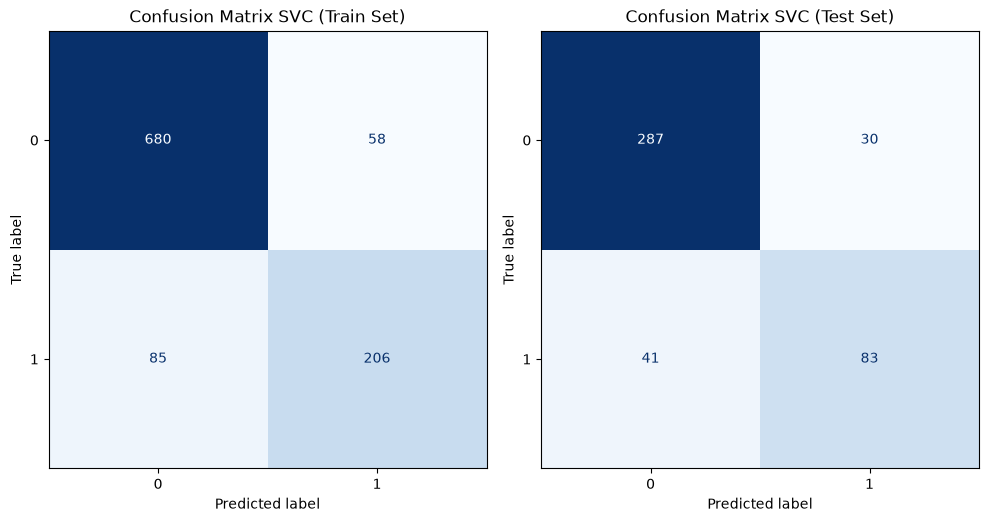

######################################################################
-----------------------MLPClassifier-----------------------
######################################################################
Cross val score from Optuna:  0.8095287710158654
Cross validation accuracy score:  0.8095287710158654
Training accuracy score:  0.8853255587949466
Testing accuracy score:  0.7936507936507936
Classification Report on Test Data
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       317
           1       0.65      0.57      0.61       124

    accuracy                           0.79       441
   macro avg       0.75      0.73      0.73       441
weighted avg       0.79      0.79      0.79       441



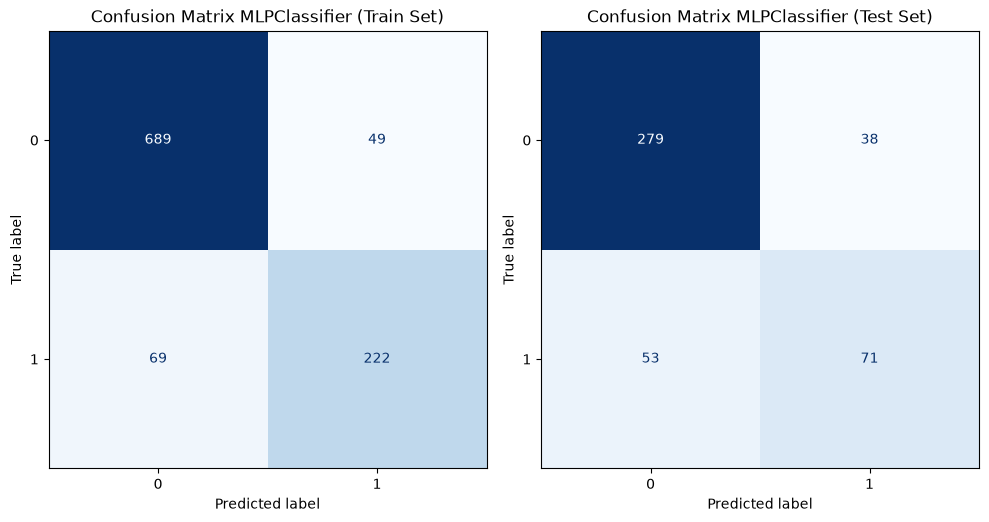

######################################################################
-----------------------RandomForestClassifier-----------------------
######################################################################
Cross val score from Optuna:  0.7958986502486385
Cross validation accuracy score:  0.7958986502486385
Training accuracy score:  0.9786200194363459
Testing accuracy score:  0.8117913832199547
Classification Report on Test Data
              precision    recall  f1-score   support

           0       0.83      0.93      0.88       317
           1       0.74      0.51      0.60       124

    accuracy                           0.81       441
   macro avg       0.78      0.72      0.74       441
weighted avg       0.80      0.81      0.80       441



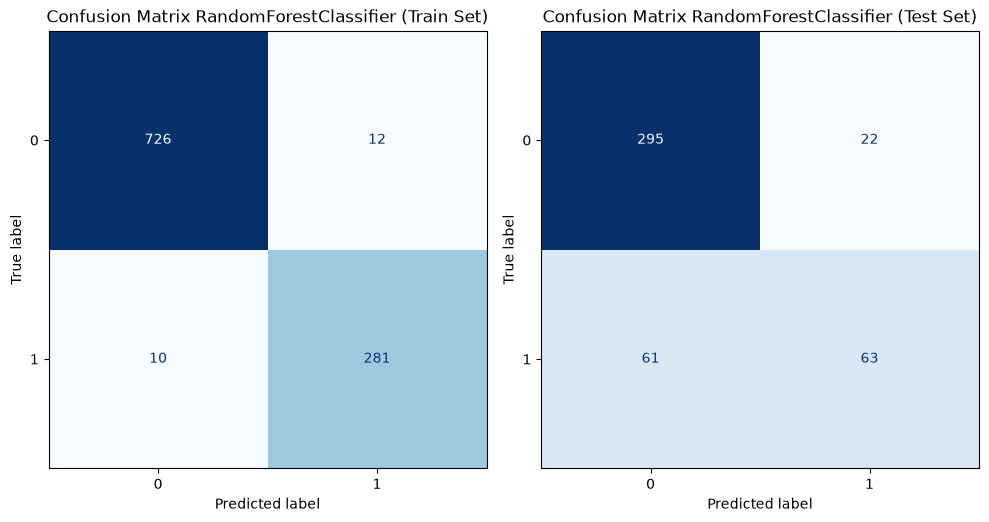

######################################################################
-----------------------HistGradientBoostingClassifier-----------------------
######################################################################
Cross val score from Optuna:  0.7978593417002131
Cross validation accuracy score:  0.7978593417002131
Training accuracy score:  0.9076773566569485
Testing accuracy score:  0.8163265306122449
Classification Report on Test Data
              precision    recall  f1-score   support

           0       0.85      0.91      0.88       317
           1       0.72      0.57      0.64       124

    accuracy                           0.82       441
   macro avg       0.78      0.74      0.76       441
weighted avg       0.81      0.82      0.81       441



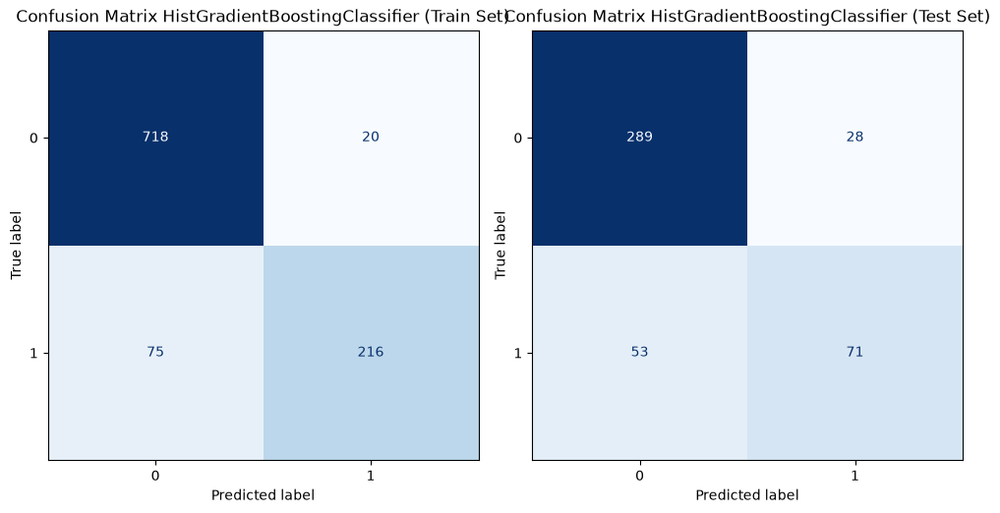

In [ ]:
def conf_matrix_traintest(y_train_true, y_train_pred, y_test_true, y_test_pred, title='Confusion Matrix'):
    cm_train = confusion_matrix(y_train_true, y_train_pred)
    cm_test = confusion_matrix(y_test_true, y_test_pred)
    fig, axes = plt.subplots(1, 2, figsize=(10,5))
    
    # training
    disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train)
    disp_train.plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'{title} (Train Set)')

    # test
    disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
    disp_test.plot(ax=axes[1], cmap='Blues', colorbar=False)
    axes[1].set_title(f'{title} (Test Set)')

    plt.tight_layout()
    plt.show()

def compute_score_crossval(model, x, y, scoring='accuracy'):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    f1 = cross_val_score(model, x, y, cv=skf,
                        scoring='accuracy')
    return np.mean(f1)

def compute_accuracy(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    
    return acc


# create model

model_names = ['SVC', 'MLPClassifier', 'RandomForestClassifier', 'HistGradientBoostingClassifier']
counter = 0
for classifier in best_classifiers:
    classifier.fit(x_train, y_train)

    print(f"######################################################################")
    print(f"-----------------------{model_names[counter]}-----------------------")
    print(f"######################################################################")
    print("Cross val score from Optuna: ", classifier_score[counter])
    print("Cross validation accuracy score: ", compute_score_crossval(classifier, x_train, y_train))
    
    # Predicting on Training Data
    y_train_pred = classifier.predict(x_train)
    print("Training accuracy score: ", compute_accuracy(y_train, y_train_pred))
    
    # Predicting on Testing Data
    y_test_pred = classifier.predict(x_test)
    print("Testing accuracy score: ", compute_accuracy(y_test, y_test_pred))

    print('Classification Report on Test Data')
    print(classification_report(y_test, y_test_pred))

    # confusion matrix
    conf_matrix_traintest(y_train, y_train_pred, y_test, y_test_pred, title=f'Confusion Matrix {model_names[counter]}')


    counter+=1
    
    

